# Diseño de completación y productividad de pozos no convencionales en Vaca Muerta

## Proyecto Final — Pre-entrega 3: modelos supervisados, evaluación y métricas

**Integrantes:** Franco Malacalza · Martín Gerbaldo · Carolina Bailón

**Curso:** EnergIA Digital 2026 — Ciencia de Datos

---

## De dónde venimos

En la Pre-entrega 2 trabajamos sobre los **datos de fractura** de la Secretaría de Energía: una fila
por operación de fractura, con el detalle del diseño de completación de cada pozo —longitud de la
rama horizontal, cantidad de etapas, arena nacional e importada, agua inyectada, presión máxima y
potencia de los equipos—. Limpiamos ese dataset, consolidamos las cargas parciales por pozo,
imputamos los valores faltantes y construimos las variables de intensidad que normalizan el diseño
por la escala del pozo.

El resultado fue un dataset de **2.603 pozos horizontales** con su diseño caracterizado. Lo que nos
faltaba era lo más importante: **cuánto produjo cada uno de esos pozos**.

## Qué hacemos en esta entrega

Esta pre-entrega cierra el círculo. Incorporamos los datos de producción mensual, construimos la
variable objetivo, y entrenamos modelos supervisados para responder la pregunta que motivó todo el
proyecto:

> **¿Cuánto petróleo va a producir un pozo en su primer año, a partir de las decisiones de diseño
> que tomamos antes de fracturarlo?**

Es un problema de **regresión supervisada**: la variable a predecir es continua (metros cúbicos de
petróleo acumulados en 12 meses) y tenemos ejemplos históricos con la respuesta conocida.

El recorrido es:

| Parte | Contenido |
|---|---|
| **1** | Datos y construcción de la variable objetivo (puntos 1 a 5) |
| **2** | Selección de variables predictoras (puntos 6 y 7) |
| **3** | Partición, preprocesamiento, métricas y encoding (puntos 8 a 11) |
| **4** | Entrenamiento y comparación de modelos (puntos 12 a 14) |
| **5** | Validación cruzada, hiperparámetros, sobreajuste y variantes (puntos 15 a 19) |
| **6** | Análisis del modelo elegido, diagnóstico de error y conclusiones (puntos 20 a 22) |

## Adelanto del resultado

El modelo explica **el 26% de la varianza** de la producción del primer año y reduce el error
absoluto medio **un 25%** respecto de predecir siempre la mediana. No es un número alto, y la parte
más valiosa de esta entrega es entender **por qué**: el mismo modelo evaluado con una partición
aleatoria da R² = 0,52, exactamente el doble. Esa diferencia no es ruido, y explicarla es el
hallazgo central de esta etapa.

# Parte 1: Datos y construcción de la variable objetivo

# 1. Preparación del entorno

Fijamos la semilla y las versiones para que el notebook sea reproducible: cualquiera que lo corra
tiene que obtener exactamente los mismos números.

In [1]:
import warnings

# Se silencian solo las dos categorias que ensucian la salida sin indicar un problema
# real: avisos de que una API de pandas o de scikit-learn va a cambiar en una version
# futura. Un RuntimeWarning —una division por cero, un desbordamiento— SI tiene que
# aparecer, y por eso no se apaga todo con un filtro general.
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)

# Este es esperado y esta documentado en el punto 11: en los cortes temporales del
# punto 19, el tramo de entrenamiento no siempre vio a todas las operadoras que
# aparecen en el año validado. handle_unknown="ignore" las codifica como todo ceros,
# que es precisamente el comportamiento que queremos.
warnings.filterwarnings("ignore", message="Found unknown categories")

from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (StandardScaler, OneHotEncoder,
                                   OrdinalEncoder, TargetEncoder)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression, RidgeCV
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import (train_test_split, TimeSeriesSplit, KFold,
                                     cross_val_score, GridSearchCV,
                                     RandomizedSearchCV)
from scipy.stats import randint, uniform
from sklearn.base import clone

SEMILLA = 42
np.random.seed(SEMILLA)

pd.set_option("display.max_columns", 80)
pd.set_option("display.width", 180)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.dpi"] = 110

def f3(x):
    """Formato de tabla: enteros con separador arriba de 1.000, 3 decimales abajo.

    Hace falta porque en la misma tabla convive un MAE de 10.596 m3 con un R2 de
    0,263: con un unico formato de dos decimales, el MAE se llena de ceros y —peor—
    el R2 se imprime como 0,26, de modo que una afirmacion del texto como "sube de
    0,263 a 0,285" no se puede verificar contra la tabla.
    """
    return f"{x:,.0f}" if abs(x) >= 1000 else f"{x:,.3f}"


pd.set_option("display.float_format", f3)

print(f"pandas       {pd.__version__}")
print(f"numpy        {np.__version__}")
print(f"scikit-learn {sklearn.__version__}")
print(f"semilla      {SEMILLA}")

pandas       3.0.5
numpy        2.5.3
scikit-learn 1.9.1
semilla      42


# 2. Las dos fuentes de datos

Esta entrega cruza dos datasets abiertos de la Secretaría de Energía:

| Fuente | Grano | Qué aporta |
|---|---|---|
| **Datos de fractura de pozos (Adjunto IV)** | una fila por operación de fractura | el **diseño** de completación: las variables predictoras |
| **Producción de pozos de gas y petróleo** | una fila por pozo y mes | la **producción**: la variable objetivo |

La clave que las une es `idpozo`.

## Una aclaración sobre el archivo de producción

El dataset de producción original son **archivos anuales que suman 1,4 GB**: cubren todos los pozos
del país, convencionales y no convencionales, desde 2006. Trabajar con eso en un notebook no es
práctico y no se puede versionar en el repositorio.

Lo que hicimos fue **filtrarlo antes de subirlo**: nos quedamos únicamente con los pozos que están
en nuestro alcance (los 2.603 pozos horizontales de la Pre-entrega 2) y con las cinco columnas que
necesitamos. El resultado es `data/produccion_filtrada.csv.gz`, de **1,3 MB**: mil veces más chico,
y con exactamente la misma información útil para nuestro problema.

El script que hace ese filtrado está documentado al final del notebook, para que el recorte sea
auditable y reproducible.

In [2]:
# Los archivos están en el repositorio. Se intenta primero la copia local, así el
# notebook corre sin conexión; si no aparece —por ejemplo al abrirlo en Colab—
# se leen directamente del repositorio por su URL.
URL_REPO = ("https://raw.githubusercontent.com/FrancoMalacalza01/"
            "preentrega-data-science/main/data/")

def leer(nombre, **kw):
    """Busca el archivo en data/ (desde la raiz o desde notebooks/); si no esta, lo baja."""
    for candidato in [Path("data") / nombre, Path("..") / "data" / nombre]:
        if candidato.exists():
            print(f"  {nombre:32s} <- {candidato}")
            return pd.read_csv(candidato, **kw)
    print(f"  {nombre:32s} <- repositorio (URL)")
    return pd.read_csv(URL_REPO + nombre, **kw)

print("Leyendo:")
fractura = leer("fractura_adjunto_iv.csv", low_memory=False)
prod = leer("produccion_filtrada.csv.gz")

print(f"\nfractura:   {fractura.shape[0]:,} filas x {fractura.shape[1]} columnas")
print(f"produccion: {prod.shape[0]:,} filas x {prod.shape[1]} columnas")
prod.head()

Leyendo:
  fractura_adjunto_iv.csv          <- ../data/fractura_adjunto_iv.csv
  produccion_filtrada.csv.gz       <- ../data/produccion_filtrada.csv.gz



fractura:   4,890 filas x 30 columnas
produccion: 136,380 filas x 5 columnas


,idpozo,anio,mes,prod_pet,prod_gas
0,162030,2021,1,"2,226",264.720
1,162029,2021,1,"2,307",298.780
2,162024,2021,1,"6,719",733.570
3,161953,2021,1,"3,425",449.150
4,161948,2021,1,"4,967",795.710


## Chequeo de integridad del archivo de producción

Antes de usarlo, verificamos que el recorte no haya introducido problemas: nulos, duplicados de
pozo-mes, o valores imposibles.

In [3]:
print(f"Pozos distintos:        {prod.idpozo.nunique():,}")
print(f"Período:                {prod.anio.min()} - {prod.anio.max()}")
print(f"Nulos:                  {prod.isna().sum().sum()}")
print(f"Duplicados de pozo-mes: {prod.duplicated(subset=['idpozo','anio','mes']).sum()}")
print(f"Producciones negativas: {(prod[['prod_pet','prod_gas']] < 0).sum().sum()}")
print(f"\nMeses fuera de 1-12:    {(~prod.mes.between(1,12)).sum()}")
prod[["prod_pet","prod_gas"]].describe()

Pozos distintos:        2,603
Período:                2006 - 2026
Nulos:                  0
Duplicados de pozo-mes: 0
Producciones negativas: 0

Meses fuera de 1-12:    0


,prod_pet,prod_gas
count,"136,380","136,380"
mean,913.634,"1,097"
std,"1,430","2,362"
min,0.000,0.000
25%,0.000,42.749
50%,344.210,175.015
75%,"1,201",817.089
max,"26,593","40,087"


El archivo está limpio: 2.603 pozos, sin nulos, sin duplicados de pozo-mes y sin valores negativos.

Una observación sobre los mínimos: hay meses con producción **cero**. No son errores —un pozo puede
estar parado por mantenimiento, o todavía no haber arrancado— y vamos a tratarlos explícitamente al
construir la variable objetivo.

# 3. Reconstruimos el dataset de diseño de la Pre-entrega 2

Para que este notebook se sostenga solo, volvemos a aplicar el pipeline de limpieza que
documentamos en la entrega anterior. Es el mismo criterio, resumido en una única celda:

1. **Fechas a formato fecha**, descartando las inconsistentes (fin antes del inicio, inicio en el futuro).
2. **Categóricas normalizadas** a minúscula sin espacios sobrantes, con `"sin dato"` para los faltantes.
3. **Filtro de alcance**: pozos horizontales con rama de al menos 500 m.
4. **Consolidación por pozo**: un pozo fracturado en varias cargas es un solo pozo. Sumamos lo
   acumulable (etapas, arena, agua) y tomamos el máximo de lo que no lo es (presión, potencia, rama).
5. **Imputación por mediana de formación** de los ceros y los extremos del 1% en presión, potencia y agua.
6. **Variables derivadas**: las de intensidad (`arena_por_metro`, `agua_por_metro`,
   `espaciamiento_etapas_m`) y las de ratio.

In [4]:
UMBRAL_RAMA_M = 500

CATEGORICAS = ["cuenca", "formacion_productiva", "tipo_reservorio", "subtipo_reservorio",
               "tipo_terminacion", "empresa_informante", "yacimiento", "areapermisoconcesion"]

# Lo que se acumula se suma; lo que describe una condición del pozo se toma al máximo.
AGREGACION = {
    "longitud_rama_horizontal_m": "max", "presion_maxima_psi": "max",
    "potencia_equipos_fractura_hp": "max", "cantidad_fracturas": "sum",
    "arena_bombeada_nacional_tn": "sum", "arena_bombeada_importada_tn": "sum",
    "agua_inyectada_m3": "sum", "fecha_inicio_fractura": "min", "fecha_fin_fractura": "max",
    "sigla": "first", "cuenca": "first", "areapermisoconcesion": "first", "yacimiento": "first",
    "formacion_productiva": "first", "tipo_reservorio": "first", "subtipo_reservorio": "first",
    "tipo_terminacion": "first", "empresa_informante": "first",
}

df = fractura.copy()

for c in ["fecha_inicio_fractura", "fecha_fin_fractura", "fecha_data"]:
    df[c] = pd.to_datetime(df[c], errors="coerce")

# Referencia para descartar fechas imposibles: la publicacion del propio archivo, no el
# reloj de la maquina. Con pd.Timestamp.today() el conteo cambiaria en cada ejecucion.
FECHA_CORTE = df.fecha_data.max()

df.loc[df.fecha_fin_fractura < df.fecha_inicio_fractura, "fecha_fin_fractura"] = pd.NaT
df.loc[df.fecha_inicio_fractura > FECHA_CORTE, "fecha_inicio_fractura"] = pd.NaT

for c in CATEGORICAS:
    df[c] = (df[c].astype(str).str.strip().str.lower()
             .replace({"nan": "sin dato", "": "sin dato"}))

df = df[df.longitud_rama_horizontal_m >= UMBRAL_RAMA_M]
pozos = df.groupby("idpozo").agg(**{k: (k, v) for k, v in AGREGACION.items()}).reset_index()

print(f"Fecha de publicacion del archivo:   {FECHA_CORTE:%Y-%m-%d}")
print(f"Registros de fractura horizontales: {len(df):,}")
print(f"Pozos distintos tras consolidar:    {len(pozos):,}")

Fecha de publicacion del archivo:   2026-09-04
Registros de fractura horizontales: 2,616
Pozos distintos tras consolidar:    2,603


In [5]:
# Imputación de ceros y faltantes por la mediana de la formación.
for c in ["presion_maxima_psi", "potencia_equipos_fractura_hp", "agua_inyectada_m3"]:
    falta = (pozos[c] == 0) | pozos[c].isna()
    mediana = pozos.loc[~falta].groupby("formacion_productiva")[c].median()
    pozos.loc[falta, c] = pozos.loc[falta, "formacion_productiva"].map(mediana)
    pozos[c] = pozos[c].fillna(pozos.loc[~falta, c].median())
    print(f"{c:30s} imputados: {falta.sum():4d}")

# Imputación de los extremos del 1% en las variables de equipo.
for c in ["presion_maxima_psi", "potencia_equipos_fractura_hp"]:
    lo, hi = pozos[c].quantile([0.01, 0.99])
    extremo = (pozos[c] < lo) | (pozos[c] > hi)
    mediana = pozos.loc[~extremo].groupby("formacion_productiva")[c].median()
    pozos.loc[extremo, c] = pozos.loc[extremo, "formacion_productiva"].map(mediana)
    pozos[c] = pozos[c].fillna(pozos.loc[~extremo, c].median())
    print(f"{c:30s} extremos reemplazados: {extremo.sum():4d}")

presion_maxima_psi             imputados:    3
potencia_equipos_fractura_hp   imputados:   44
agua_inyectada_m3              imputados:    3
presion_maxima_psi             extremos reemplazados:   54
potencia_equipos_fractura_hp   extremos reemplazados:   26


In [6]:
# Variables derivadas: intensidad del diseño y ratios.
pozos["arena_total_tn"] = (pozos.arena_bombeada_nacional_tn
                           + pozos.arena_bombeada_importada_tn)
pozos["arena_por_metro"] = pozos.arena_total_tn / pozos.longitud_rama_horizontal_m
pozos["agua_por_metro"] = pozos.agua_inyectada_m3 / pozos.longitud_rama_horizontal_m
pozos["arena_por_etapa"] = pozos.arena_total_tn / pozos.cantidad_fracturas
pozos["agua_por_etapa"] = pozos.agua_inyectada_m3 / pozos.cantidad_fracturas
pozos["espaciamiento_etapas_m"] = (pozos.longitud_rama_horizontal_m
                                   / pozos.cantidad_fracturas)
pozos["ratio_arena_importada"] = (pozos.arena_bombeada_importada_tn
                                  / pozos.arena_total_tn.replace(0, np.nan)).fillna(0)
pozos["ratio_agua_arena"] = (pozos.agua_inyectada_m3
                             / pozos.arena_total_tn.replace(0, np.nan))
pozos["usa_arena_importada"] = (pozos.arena_bombeada_importada_tn > 0).astype(int)
pozos["duracion_fractura_dias"] = (pozos.fecha_fin_fractura
                                   - pozos.fecha_inicio_fractura).dt.days
pozos["anio_fractura"] = pozos.fecha_inicio_fractura.dt.year

print(f"Dataset de diseño: {pozos.shape[0]:,} pozos x {pozos.shape[1]} variables")
pozos[["idpozo", "anio_fractura", "longitud_rama_horizontal_m", "cantidad_fracturas",
       "arena_por_metro", "agua_por_metro", "espaciamiento_etapas_m"]].head()

Dataset de diseño: 2,603 pozos x 30 variables


,idpozo,anio_fractura,longitud_rama_horizontal_m,cantidad_fracturas,arena_por_metro,agua_por_metro,espaciamiento_etapas_m
0,131726,"2,009",980.000,6,0.385,2.073,163.333
1,133184,"2,009",910.000,5,0.201,1.908,182.000
2,133425,"2,010",990.000,6,0.496,1.688,165.000
3,133986,"2,010","1,010",5,0.176,1.543,202.000
4,134766,"2,010","1,170",5,0.197,0.910,234.000


# 4. Construcción de la variable objetivo

Acá está la decisión más importante del notebook. "Cuánto produce un pozo" puede medirse de muchas
formas, y cada una define un problema distinto.

## Qué medimos y por qué

Elegimos **los metros cúbicos de petróleo acumulados en los primeros 12 meses de producción**.

Las razones:

- **Es comparable entre pozos.** Un pozo de 2019 y uno de 2024 no se pueden comparar por producción
  total acumulada: el de 2019 lleva cinco años más produciendo. Los primeros 12 meses sí son
  comparables, porque miden la misma ventana de vida del pozo.
- **Es el indicador que usa la industria.** La productividad inicial es lo que determina la
  recuperación del capital invertido en la completación.
- **Es lo que se decide al diseñar.** El diseño de fractura condiciona sobre todo la productividad
  temprana; a varios años la declinación natural domina.

## Los primeros 12 meses, no los primeros 12 meses del calendario

`mes_de_vida` tiene que contarse desde el **primer mes con producción efectiva** de cada pozo, y
calcularse como **diferencia de períodos**, no como la posición de la fila.

La diferencia importa: si usáramos un contador de filas (`cumcount`), un pozo que estuvo parado tres
meses tendría su "mes 12" recién en el mes 15 de vida real. Estaríamos comparando ventanas de distinta
duración. Calculándolo por diferencia de fechas, el mes 12 es el mes 12 para todos.

In [7]:
prod["periodo"] = pd.to_datetime(
    dict(year=prod.anio, month=prod.mes, day=1)).dt.to_period("M")

# Solo meses con produccion efectiva de petroleo: el arranque del pozo es el primero de ellos.
activos = prod[prod.prod_pet > 0].copy()
primer_mes = activos.groupby("idpozo").periodo.min().rename("primer_mes")
activos = activos.merge(primer_mes, on="idpozo")

# Mes de vida por DIFERENCIA DE PERIODOS, no por posicion de fila.
activos["mes_de_vida"] = (
    (activos.periodo.dt.year - activos.primer_mes.dt.year) * 12
    + (activos.periodo.dt.month - activos.primer_mes.dt.month) + 1)

ventana = activos[activos.mes_de_vida.between(1, 12)]

objetivo = ventana.groupby("idpozo").agg(
    prod_pet_acum_12m=("prod_pet", "sum"),
    prod_gas_acum_12m=("prod_gas", "sum"),
    meses_con_produccion=("prod_pet", "size"),
    primer_mes=("primer_mes", "first")).reset_index()

print(f"Pozos con al menos un mes de produccion: {len(objetivo):,}")
objetivo.head()

Pozos con al menos un mes de produccion: 2,402


,idpozo,prod_pet_acum_12m,prod_gas_acum_12m,meses_con_produccion,primer_mes
0,131726,222.327,"8,149",12,2021-03
1,134766,510.036,"33,960",12,2010-10
2,134903,583.870,"8,314",8,2011-01
3,135066,428.969,"32,250",12,2010-12
4,137008,"11,747","1,888",12,2012-01


## Los dos guardas de truncamiento

Un pozo solo entra al dataset de modelado si su ventana de 12 meses está **completa dentro del
rango de datos disponible**. Si no, el acumulado que calculamos no sería de 12 meses y el modelo
aprendería de una respuesta mal medida.

Hay dos formas de que la ventana quede incompleta:

- **Truncamiento a izquierda**: el pozo ya producía antes de que empiece el archivo. Su "primer mes"
  aparente no es el real, y el acumulado correspondería a una etapa posterior de su vida.
- **Truncamiento a derecha**: el pozo arrancó hace menos de 12 meses. Todavía no cumplió el año.

El truncamiento a derecha es el que más pozos descarta, y es inevitable: los pozos más nuevos son
justamente los que tienen el diseño más moderno, pero no podemos usarlos porque no sabemos todavía
cuánto van a producir.

In [8]:
p_min, p_max = prod.periodo.min(), prod.periodo.max()
print(f"Rango del archivo de produccion: {p_min} a {p_max}")

trunc_izq = objetivo.primer_mes <= p_min
trunc_der = (objetivo.primer_mes + 11) > p_max   # +11 meses sobre un periodo mensual

print(f"\nTruncados a izquierda (ya producian al inicio del archivo): {trunc_izq.sum():,}")
print(f"Truncados a derecha (arrancaron hace menos de 12 meses):    {trunc_der.sum():,}")

objetivo = objetivo[~trunc_izq & ~trunc_der].copy()
print(f"\nPozos con ventana de 12 meses completa y verificable: {len(objetivo):,}")

Rango del archivo de produccion: 2006-01 a 2026-09

Truncados a izquierda (ya producian al inicio del archivo): 0
Truncados a derecha (arrancaron hace menos de 12 meses):    294

Pozos con ventana de 12 meses completa y verificable: 2,108


No hay ningún pozo truncado a izquierda: el archivo de producción arranca en 2006 y el primer pozo
horizontal de nuestro alcance se fracturó en 2009, así que todos tienen su historia completa desde
el arranque.

In [9]:
# Cruce del diseño con la produccion: este es el dataset de modelado.
datos = pozos.merge(objetivo, on="idpozo", how="inner")

print(f"Pozos con diseño (Pre-entrega 2): {len(pozos):,}")
print(f"Pozos con objetivo medible:       {len(objetivo):,}")
print(f"Dataset de modelado:              {len(datos):,} "
      f"({len(datos)/len(pozos):.0%} de los pozos del alcance)")
print(f"\nMeses efectivamente produciendo dentro de la ventana de 12:")
print(datos.meses_con_produccion.value_counts().sort_index().to_string())

Pozos con diseño (Pre-entrega 2): 2,603
Pozos con objetivo medible:       2,108
Dataset de modelado:              2,108 (81% de los pozos del alcance)

Meses efectivamente produciendo dentro de la ventana de 12:
meses_con_produccion
1       25
2        8
3       11
4        8
5       15
6       10
7       11
8       31
9       24
10      42
11     165
12    1758


**2.108 pozos con variable objetivo medible**, el 81% del alcance de la Pre-entrega 2. Los 495 que
quedan afuera se reparten en dos grupos: **294 son pozos fracturados en los últimos meses**, que
todavía no cumplieron el año, y los **201 restantes no tienen ningún mes con producción de petróleo
registrada** en el archivo —pozos que no llegaron a producir, o que producen solo gas—. Son dos
motivos distintos de exclusión y conviene no confundirlos: el primero es truncamiento y se corrige
con el tiempo; el segundo no.

De los 2.108, **1.758 produjeron los 12 meses completos**. Los demás tuvieron algún mes parado. Los
mantenemos: un mes de mantenimiento es parte normal de la operación de un pozo y descartarlos
sesgaría el dataset hacia los pozos sin incidentes. El acumulado de 12 meses ya los penaliza
correctamente, porque suma menos.

## Cómo se distribuye la variable objetivo

In [10]:
y = datos.prod_pet_acum_12m
print("Produccion de petroleo acumulada a 12 meses (m3)")
print(y.describe().to_string())
print(f"\nAsimetria (skewness): {y.skew():.2f}")
print(f"Curtosis:             {y.kurtosis():.2f}")
print(f"Coef. de variacion:   {y.std()/y.mean():.2f}")
print(f"\nPozos con produccion menor a 1.000 m3: {(y < 1000).sum():,}")

Produccion de petroleo acumulada a 12 meses (m3)
count     2,108
mean     28,789
std      19,406
min       0.080
25%      13,879
50%      29,494
75%      41,697
max     182,096

Asimetria (skewness): 0.57
Curtosis:             1.73
Coef. de variacion:   0.67

Pozos con produccion menor a 1.000 m3: 195


## Una hipótesis inicial que los datos desmintieron

Al plantear el proyecto habíamos anticipado que la variable objetivo iba a estar muy sesgada a
derecha y que haría falta una **transformación logarítmica** para modelarla, como es habitual en
producción de hidrocarburos.

Los datos no lo confirman, y vale la pena mostrar la verificación en lugar de arrastrar el supuesto.

In [11]:
comparacion = pd.DataFrame({
    "transformacion": ["original (m3)", "logaritmica log1p", "raiz cuadrada"],
    "asimetria": [y.skew(), np.log1p(y).skew(), np.sqrt(y).skew()],
})
comparacion["|asimetria|"] = comparacion.asimetria.abs()
print(comparacion.to_string(index=False))

   transformacion  asimetria  |asimetria|
    original (m3)      0.571        0.571
logaritmica log1p     -2.442        2.442
    raiz cuadrada     -0.610        0.610


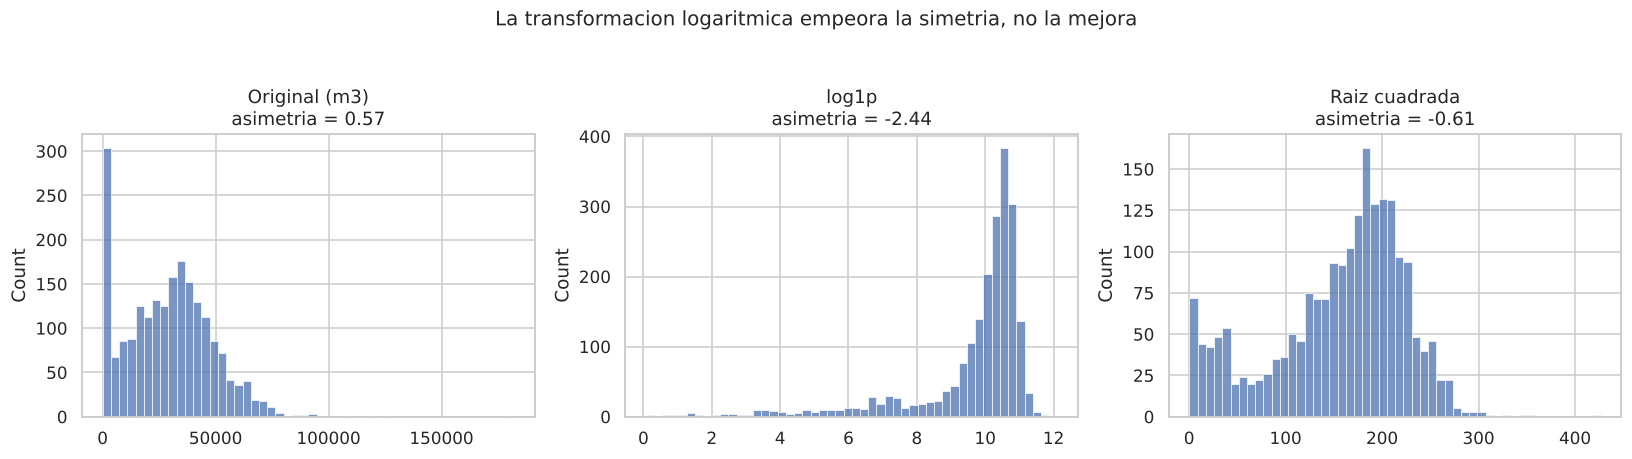

In [12]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
for a, (serie, titulo) in zip(ax, [(y, "Original (m3)"),
                                   (np.log1p(y), "log1p"),
                                   (np.sqrt(y), "Raiz cuadrada")]):
    sns.histplot(serie, bins=50, ax=a, color="#4C72B0")
    a.set_title(f"{titulo}\nasimetria = {serie.skew():.2f}")
    a.set_xlabel("")
fig.suptitle("La transformacion logaritmica empeora la simetria, no la mejora",
             fontsize=13, y=1.04)
plt.tight_layout(); plt.show()

**La asimetría original es 0,57: la variable ya es prácticamente simétrica.** Aplicarle `log1p` la
lleva a **−2,44**, es decir, la sesga fuerte hacia el otro lado y la empeora. La raíz cuadrada da
−0,61, apenas distinto del original en valor absoluto.

La razón se ve en el histograma: hay un grupo de pozos con producción de petróleo cercana a cero.
En escala original son simplemente valores bajos; el logaritmo los estira hacia menos infinito y
genera la cola izquierda larga que no estaba.

**Decisión: modelamos la variable en su escala original.** No aplicamos ninguna transformación. Esto
además tiene una ventaja práctica: las métricas de error (MAE, RMSE) quedan directamente en metros
cúbicos y son interpretables sin deshacer transformaciones.

Igual vamos a volver sobre esto: en el punto 19 probamos la raíz cuadrada como variante, para no
descartarla solo por el estadístico de asimetría.

# 5. Los pozos cuyo objetivo es el gas

Ese grupo de pozos con petróleo cercano a cero merece una mirada aparte antes de modelar.

In [13]:
datos["ratio_gas_pet"] = (datos.prod_gas_acum_12m
                          / datos.prod_pet_acum_12m.replace(0, np.nan))
datos["es_pozo_de_gas"] = ((datos.prod_pet_acum_12m < 1000)
                           & (datos.ratio_gas_pet > 5)).astype(int)

resumen = datos.groupby("es_pozo_de_gas").agg(
    pozos=("idpozo", "size"),
    pet_mediana=("prod_pet_acum_12m", "median"),
    gas_mediana=("prod_gas_acum_12m", "median"),
    rama_mediana=("longitud_rama_horizontal_m", "median"))
resumen.index = ["pozos de petroleo", "pozos de gas"]
print(resumen.to_string())
print(f"\nPozos de gas: {datos.es_pozo_de_gas.sum():,} "
      f"({datos.es_pozo_de_gas.mean():.1%} del dataset)")

                   pozos  pet_mediana  gas_mediana  rama_mediana
pozos de petroleo   1917       31,872        5,065         2,517
pozos de gas         191      177.589       29,135         1,884

Pozos de gas: 191 (9.1% del dataset)


Son **191 pozos, el 9,1% del dataset**, y no son pozos de petróleo fallidos: su mediana de gas es
**29.135 miles de m³ contra 5.065** del resto, casi seis veces más. Tienen una rama comparable y un
diseño de fractura comparable. Lo que cambia es el **objetivo**: se perforaron para producir gas.

Medirlos con la variable "petróleo acumulado a 12 meses" es evaluarlos con la métrica equivocada.
Un pozo de gas con 180 m³ de petróleo no es un fracaso; es un pozo que hizo lo que tenía que hacer.

**Decisión: los excluimos del modelo de petróleo y lo dejamos documentado.** Dejarlos adentro
metería 191 ceros que el modelo intentaría explicar con variables de diseño que no los explican,
porque la diferencia no está en el diseño sino en la geología objetivo.

In [14]:
modelado = datos[datos.es_pozo_de_gas == 0].copy()

print(f"Dataset final de modelado: {modelado.shape[0]:,} pozos")
print(f"Años de fractura:          {modelado.anio_fractura.min():.0f} - "
      f"{modelado.anio_fractura.max():.0f}")
print(f"\nPozos por año de fractura:")
print(modelado.anio_fractura.value_counts().sort_index().to_string())

Dataset final de modelado: 1,917 pozos
Años de fractura:          2011 - 2025

Pozos por año de fractura:
anio_fractura
2,011      1
2,012      4
2,013      4
2,014     11
2,015     33
2,016     85
2,017     95
2,018    128
2,019    164
2,020     79
2,021    188
2,022    240
2,023    266
2,024    321
2,025    298


# Parte 2: Selección de variables predictoras

# 6. Las variables que no sirven

Antes de elegir qué entra al modelo, sacamos lo que no puede aportar nada. Dos filtros.

## Variables sin varianza

Después del filtro de alcance de la Pre-entrega 2 —pozos horizontales de Vaca Muerta— varias
categóricas quedaron prácticamente constantes. Una variable que vale lo mismo en todos los pozos no
puede explicar por qué unos producen más que otros.

In [15]:
for c in ["tipo_reservorio", "cuenca", "formacion_productiva", "tipo_terminacion"]:
    vc = modelado[c].value_counts()
    print(f"{c:24s} {vc.iloc[0]/len(modelado):6.1%} en '{vc.index[0]}'  "
          f"({modelado[c].nunique()} categorias distintas)")

tipo_reservorio          100.0% en 'no convencional'  (1 categorias distintas)
cuenca                    99.7% en 'neuquina'  (2 categorias distintas)
formacion_productiva      99.1% en 'vaca muerta'  (5 categorias distintas)
tipo_terminacion          84.1% en 'tapón disparo'  (5 categorias distintas)


`tipo_reservorio` es **no convencional en el 100%** de los casos, `cuenca` es **neuquina en el
99,7%** y `formacion_productiva` es **vaca muerta en el 99,1%**. Las tres quedan afuera.

Esto tiene una consecuencia práctica para el modelo de referencia: habíamos pensado usar la mediana
por formación como línea base, pero si el 99% de los pozos son de la misma formación, esa mediana
es la mediana global. Usamos directamente la mediana global, que es más honesta.

## Variables que no están disponibles al decidir

El modelo tiene que servir **antes de fracturar el pozo**. Cualquier variable que solo se conozca
después no puede entrar, aunque mejore las métricas: usarla sería hacer trampa con información del
futuro.

Quedan afuera por este criterio:

| Variable | Por qué |
|---|---|
| `prod_gas_acum_12m` | es producción: se conoce al mismo tiempo que el objetivo |
| `meses_con_produccion` | depende de la operación posterior del pozo |
| `ratio_gas_pet`, `es_pozo_de_gas` | derivadas de la producción |
| `primer_mes` | fecha del arranque, posterior a la fractura |

`duracion_fractura_dias` sí la dejamos: se conoce al terminar la fractura, antes de que el pozo
produzca, y es una señal legítima de cómo salió la operación.

# 7. El problema de la multicolinealidad

En la Pre-entrega 2 encontramos correlaciones de **0,91** entre longitud de rama, cantidad de etapas
y arena total. Tiene sentido físico: un pozo con el doble de rama lleva el doble de etapas y el doble
de arena. Las tres miden lo mismo, que es **la escala de la operación**.

Para un modelo esto es un problema concreto: con variables casi idénticas, el modelo reparte el
efecto entre ellas de forma arbitraria. Los coeficientes se vuelven inestables y dejan de ser
interpretables, y pequeñas variaciones en los datos pueden incluso cambiarles el signo.

Lo medimos con el **VIF** (factor de inflación de la varianza): para cada variable, se regresa contra
todas las demás y se calcula `1/(1-R²)`. Un VIF de 10 significa que el 90% de esa variable ya está
explicado por las otras.

In [16]:
def vif(df, columnas):
    """VIF = 1/(1-R2) de regresar cada variable contra todas las demas."""
    X = df[columnas].dropna().to_numpy(float)
    resultado = {}
    for i, c in enumerate(columnas):
        objetivo_i = X[:, i]
        resto = np.column_stack([np.ones(len(X)), np.delete(X, i, axis=1)])
        beta, *_ = np.linalg.lstsq(resto, objetivo_i, rcond=None)
        r2 = 1 - ((objetivo_i - resto @ beta)**2).sum() / \
                 ((objetivo_i - objetivo_i.mean())**2).sum()
        resultado[c] = 1 / max(1e-12, 1 - r2)
    return pd.Series(resultado).sort_values(ascending=False).round(2)

CRUDAS = ["longitud_rama_horizontal_m", "cantidad_fracturas", "arena_total_tn",
          "agua_inyectada_m3", "presion_maxima_psi", "potencia_equipos_fractura_hp"]
print("VIF usando las variables crudas del dataset:")
print(vif(modelado, CRUDAS).to_string())

VIF usando las variables crudas del dataset:
cantidad_fracturas             7.570
agua_inyectada_m3              5.010
longitud_rama_horizontal_m     4.260
arena_total_tn                 2.460
presion_maxima_psi             1.220
potencia_equipos_fractura_hp   1.070


## La solución: una variable de escala más las de intensidad

En vez de elegir entre rama, etapas y arena —las tres dicen lo mismo— separamos los dos conceptos
que estaban mezclados:

- **Cuán grande es la operación**: lo resume `longitud_rama_horizontal_m`. La elegimos porque es la
  decisión más temprana y menos ambigua del diseño.
- **Cuán intensa es la fractura por unidad de escala**: las variables de intensidad que construimos
  en la Pre-entrega 2, `arena_por_metro`, `agua_por_metro` y `espaciamiento_etapas_m`.

La información no se pierde: `arena_total_tn` es aproximadamente `arena_por_metro × rama`, así que
el modelo puede reconstruirla. Lo que ganamos es que las dos piezas ya no están confundidas.

In [17]:
NUMERICAS = ["longitud_rama_horizontal_m",     # escala de la operacion
             "arena_por_metro",                # intensidad: arena
             "agua_por_metro",                 # intensidad: agua
             "espaciamiento_etapas_m",         # intensidad: densidad de etapas
             "ratio_agua_arena",               # tipo de fluido (slickwater vs gel)
             "ratio_arena_importada",          # calidad de la arena
             "presion_maxima_psi",             # condicion de la roca y del bombeo
             "potencia_equipos_fractura_hp",   # capacidad del equipo
             "duracion_fractura_dias"]         # como salio la operacion

print("VIF con el set elegido:")
print(vif(modelado, NUMERICAS).to_string())

VIF con el set elegido:
agua_por_metro                 4.020
ratio_agua_arena               2.690
arena_por_metro                1.860
longitud_rama_horizontal_m     1.420
ratio_arena_importada          1.390
presion_maxima_psi             1.300
espaciamiento_etapas_m         1.210
duracion_fractura_dias         1.080
potencia_equipos_fractura_hp   1.070


**Todos los VIF bajan de 5** y la mayoría está por debajo de 2. El más alto es `agua_por_metro`
(4,02), compartiendo información con `ratio_agua_arena`, pero en un nivel que ya no distorsiona.
Comparado con el set crudo, donde `cantidad_fracturas` llegaba a 7,57, el set es sustancialmente
más estable.

## La variable categórica: la operadora

Agregamos `empresa_informante`. No es una variable de diseño, y por eso la discutimos aparte.

Lo que la operadora captura es todo lo que no está en el dataset: **la calidad del área que le
tocó** y sus prácticas operativas no documentadas. Es un *proxy* de la geología, que es el factor
que más explica la productividad de un pozo y que nuestros datos no tienen.

Agrupamos las operadoras con menos de 40 pozos en una categoría `"otras"`, para no generar columnas
con tres o cuatro casos que el modelo memorizaría.

In [18]:
conteo = modelado.empresa_informante.value_counts()
modelado["operadora"] = modelado.empresa_informante.where(
    modelado.empresa_informante.map(conteo) >= 40, "otras")

CATEGORICAS_MODELO = ["operadora"]
OBJETIVO = "prod_pet_acum_12m"

print(f"Operadoras despues de agrupar: {modelado.operadora.nunique()}")
print(modelado.operadora.value_counts().to_string())

Operadoras despues de agrupar: 10
operadora
ypf s.a.                         1074
shell argentina s.a.              156
tecpetrol s.a.                    150
vista energy argentina sau        121
otras                             100
pluspetrol s.a.                   100
vista oil & gas argentina sau      62
pan american energy sl             58
total austral s.a.                 54
phoenix global resources s.a.      42


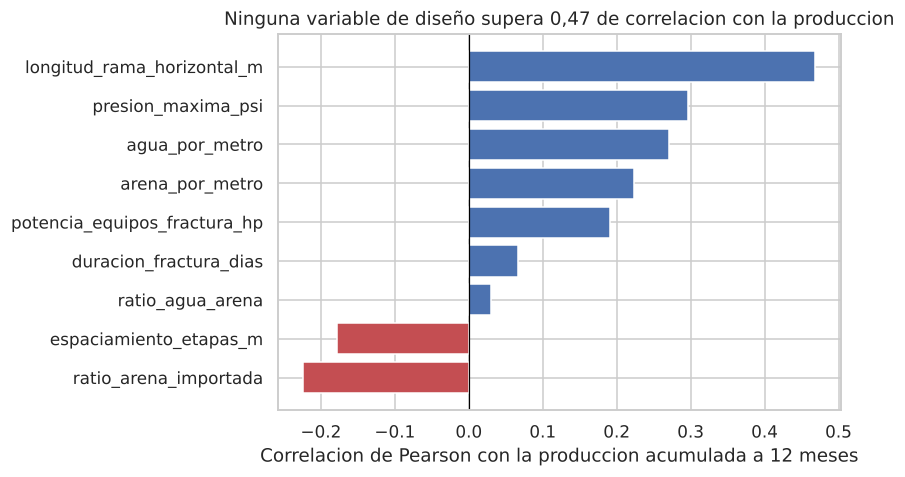

longitud_rama_horizontal_m      0.468
presion_maxima_psi              0.296
agua_por_metro                  0.270
arena_por_metro                 0.224
potencia_equipos_fractura_hp    0.191
duracion_fractura_dias          0.066
ratio_agua_arena                0.030
espaciamiento_etapas_m         -0.178
ratio_arena_importada          -0.224


In [19]:
# Correlacion de cada predictora con el objetivo, como primera lectura.
corr = (modelado[NUMERICAS + [OBJETIVO]].corr(numeric_only=True)[OBJETIVO]
        .drop(OBJETIVO).sort_values(ascending=False))

fig, ax = plt.subplots(figsize=(8, 4.5))
colores = ["#4C72B0" if v > 0 else "#C44E52" for v in corr.values]
ax.barh(corr.index[::-1], corr.values[::-1], color=colores[::-1])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Correlacion de Pearson con la produccion acumulada a 12 meses")
ax.set_title("Ninguna variable de diseño supera 0,47 de correlacion con la produccion")
plt.tight_layout(); plt.show()

print(corr.round(3).to_string())

Vale la pena detenerse en este gráfico, porque anticipa el resultado de todo el notebook.

**La correlación más alta es 0,47** (longitud de rama) y las de intensidad están entre 0,22 y 0,27.
Ninguna variable de diseño, por sí sola, explica gran parte de la producción. El diseño importa,
pero lo que más determina cuánto produce un pozo —la calidad de la roca en ese punto exacto del
subsuelo— no está en nuestros datos.

Esto marca un **techo** para cualquier modelo que entrenemos. No es un problema de método: es el
límite de la información disponible. Conviene tenerlo presente al leer las métricas.

Dos signos negativos que sí tienen lectura técnica:

- **`espaciamiento_etapas_m` (−0,18)**: más metros entre etapas es menos etapas por metro, es decir
  una fractura menos intensa. Que sea negativo confirma que fracturar más denso produce más.
- **`ratio_arena_importada` (−0,22)**: no es que la arena importada sea peor. Lo más probable es que
  esté marcando una época: se usaba más arena importada cuando los diseños todavía eran menos
  intensos.

# Parte 3: Partición de los datos, modelo de referencia y encoding

# 8. Por qué la partición es temporal y no aleatoria

Lo habitual es partir los datos al azar: 70% para entrenar, 30% para evaluar. Acá eso **sobreestima**
lo que el modelo realmente sabe hacer, y conviene explicar por qué.

El diseño de completación en Vaca Muerta **cambió muchísimo en diez años**. Los pozos de 2016 y los
de 2025 son operaciones distintas.

In [20]:
deriva = modelado.groupby("anio_fractura").agg(
    pozos=("idpozo", "size"),
    rama_m=("longitud_rama_horizontal_m", "median"),
    arena_t_m=("arena_por_metro", "median"),
    agua_m3_m=("agua_por_metro", "median"),
    espaciado_m=("espaciamiento_etapas_m", "median"),
    produccion_m3=(OBJETIVO, "median")).loc[2016:]
print(deriva.round(2).to_string())

               pozos  rama_m  arena_t_m  agua_m3_m  espaciado_m  produccion_m3
anio_fractura                                                                 
2,016             85   1,411      2.950     14.130       78.660         17,104
2,017             95   1,548      2.870     17.090       78.410         16,871
2,018            128   2,031      3.000     18.820       77.670         14,199
2,019            164   2,216      3.650     22.290       65.600         31,085
2,020             79   2,328      3.640     21.870       65.600         34,464
2,021            188   2,536      3.460     21.230       66.030         36,908
2,022            240   2,583      3.690     22.360       63.320         37,305
2,023            266   2,789      3.810     23.740       60.360         33,005
2,024            321   2,920      3.920     23.400       60.530         35,120
2,025            298   2,996      3.930     24.020       60.200         36,350


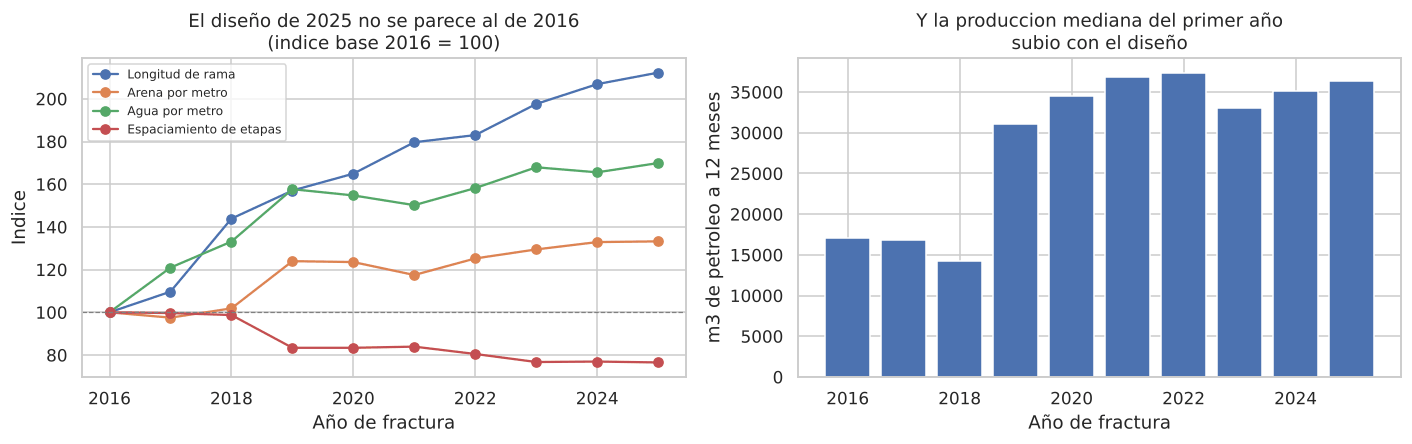

In [21]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.2))

base = deriva.loc[2016]
for col, etiqueta in [("rama_m", "Longitud de rama"),
                      ("arena_t_m", "Arena por metro"),
                      ("agua_m3_m", "Agua por metro"),
                      ("espaciado_m", "Espaciamiento de etapas")]:
    ax[0].plot(deriva.index, deriva[col] / base[col] * 100, marker="o", label=etiqueta)
ax[0].axhline(100, color="gray", ls="--", lw=0.8)
ax[0].set_title("El diseño de 2025 no se parece al de 2016\n(indice base 2016 = 100)")
ax[0].set_ylabel("Indice"); ax[0].set_xlabel("Año de fractura")
ax[0].legend(fontsize=8)

ax[1].bar(deriva.index, deriva.produccion_m3, color="#4C72B0")
ax[1].set_title("Y la produccion mediana del primer año\nsubio con el diseño")
ax[1].set_ylabel("m3 de petroleo a 12 meses"); ax[1].set_xlabel("Año de fractura")

plt.tight_layout(); plt.show()

La rama mediana pasó de **1.411 m en 2016 a 2.996 m en 2025**: se duplicó. La producción mediana del
primer año pasó de **17.104 a 36.350 m³**: también se duplicó.

Con una partición aleatoria, el conjunto de test tendría pozos de 2025 **y** el de entrenamiento
también. El modelo vería diseños modernos durante el entrenamiento y después se evaluaría sobre
pozos del mismo período. Eso no es lo que va a pasar cuando se use de verdad: en producción el
modelo se entrena con lo que ya produjo y se aplica a pozos que se van a fracturar ahora, con
diseños que todavía no vio.

**Partimos por año de fractura.** Entrenamos con todo lo anterior a 2024 y evaluamos sobre
2024-2025. Es más exigente y es la única forma de saber si el modelo sirve para lo que lo queremos.

In [22]:
CORTE = 2024
train = modelado[modelado.anio_fractura < CORTE].copy()
test = modelado[modelado.anio_fractura >= CORTE].copy()

X_train, y_train = train[NUMERICAS + CATEGORICAS_MODELO], train[OBJETIVO]
X_test, y_test = test[NUMERICAS + CATEGORICAS_MODELO], test[OBJETIVO]

print(f"Entrenamiento: {len(train):,} pozos  (fracturados hasta {CORTE-1})")
print(f"Prueba:        {len(test):,} pozos  (fracturados en {CORTE} y despues)")
print(f"Proporcion de test: {len(test)/len(modelado):.1%}")

print(f"\n{'':22s}{'train':>12s}{'test':>12s}")
for etiqueta, f in [("media (m3)", "mean"), ("mediana (m3)", "median"),
                    ("desvio (m3)", "std")]:
    print(f"{etiqueta:22s}{getattr(y_train, f)():>12,.0f}{getattr(y_test, f)():>12,.0f}")
print(f"{'rama mediana (m)':22s}{train.longitud_rama_horizontal_m.median():>12,.0f}"
      f"{test.longitud_rama_horizontal_m.median():>12,.0f}")

Entrenamiento: 1,298 pozos  (fracturados hasta 2023)
Prueba:        619 pozos  (fracturados en 2024 y despues)
Proporcion de test: 32.3%

                             train        test
media (m3)                  29,428      36,237
mediana (m3)                28,853      35,681
desvio (m3)                 17,976      17,284
rama mediana (m)             2,369       2,962


Hay que anotar algo que condiciona toda la evaluación: **el test no tiene la misma distribución que
el entrenamiento**. La media de producción es de 29.428 m³ en train y **36.237 m³ en test**, un 23%
más alta. Las ramas también son más largas.

Esto es exactamente el desplazamiento que queríamos capturar, no un error de la partición. Pero
significa que el modelo tiene que **extrapolar**: predecir sobre pozos más grandes y más productivos
que todos los que vio al entrenar. Vamos a ver que eso le cuesta, y a cuantificar cuánto.

# 9. El preprocesamiento, dentro del pipeline

Una precaución que importa: el preprocesamiento se aprende **solo con los datos de entrenamiento**.

Si imputáramos los faltantes con la mediana de todo el dataset, o escaláramos con la media de todo
el dataset, el conjunto de test estaría influyendo en la preparación de los datos con los que se
entrena el modelo. Eso es *data leakage*, y la consecuencia es que las métricas de test salen mejores
de lo que corresponde.

La forma de evitarlo es meter el preprocesamiento **dentro de un `Pipeline`**: así `fit()` lo ajusta
con train y `predict()` solo lo aplica.

Armamos dos preprocesadores distintos, porque los modelos tienen necesidades distintas:

| | Modelos lineales | Modelos de árboles |
|---|---|---|
| Faltantes | mediana de train | mediana de train |
| Escala | estandarizada (media 0, desvío 1) | sin escalar: a un árbol no le afecta |
| Categóricas | one-hot sin la primera columna | one-hot completo |

In [23]:
pre_lineal = ColumnTransformer([
    ("num", Pipeline([("imputar", SimpleImputer(strategy="median")),
                      ("escalar", StandardScaler())]), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore", drop="first"), CATEGORICAS_MODELO)])

pre_arbol = ColumnTransformer([
    ("num", SimpleImputer(strategy="median"), NUMERICAS),
    ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS_MODELO)])

print(f"Faltantes a imputar en train: "
      f"{X_train[NUMERICAS].isna().sum().sum()} "
      f"(todos en duracion_fractura_dias)")
print(f"handle_unknown='ignore': si en test apareciera una operadora "
      f"que no esta en train, no rompe.")

Faltantes a imputar en train: 8 (todos en duracion_fractura_dias)
handle_unknown='ignore': si en test apareciera una operadora que no esta en train, no rompe.


# 10. Las métricas y el modelo de referencia

## Qué métricas usamos y qué mide cada una

| Métrica | Qué mide | Unidad |
|---|---|---|
| **MAE** | error absoluto medio: en promedio, cuánto nos equivocamos | m³ |
| **RMSE** | error cuadrático medio: penaliza más los errores grandes | m³ |
| **R²** | proporción de la varianza del objetivo que el modelo explica | adimensional |

Las usamos juntas porque dicen cosas distintas. El MAE es el más interpretable: "nos equivocamos en
promedio por X m³". El RMSE castiga los errores grandes, así que si está muy por encima del MAE hay
pozos donde el modelo falla fuerte. El R² permite comparar contra no tener modelo.

No usamos **MAPE** (error porcentual): con pozos de producción cercana a cero el porcentaje se va a
infinito y la métrica deja de significar nada.

In [24]:
def metricas(y_real, y_pred):
    return {"MAE": mean_absolute_error(y_real, y_pred),
            "RMSE": mean_squared_error(y_real, y_pred) ** 0.5,
            "R2": r2_score(y_real, y_pred)}

def evaluar(nombre, modelo, resultados):
    """Entrena, mide en train y en test, y guarda todo en un unico lugar."""
    modelo.fit(X_train, y_train)
    en_train = metricas(y_train, modelo.predict(X_train))
    en_test = metricas(y_test, modelo.predict(X_test))
    resultados[nombre] = {**{f"{k}_train": v for k, v in en_train.items()},
                          **{f"{k}_test": v for k, v in en_test.items()}}
    print(f"{nombre:26s} test -> MAE {en_test['MAE']:8,.0f} m3   "
          f"RMSE {en_test['RMSE']:8,.0f} m3   R2 {en_test['R2']:6.3f}")
    return modelo

resultados = {}

## El modelo de referencia

Antes de entrenar nada hay que fijar la vara: **¿qué tan bien se puede predecir sin modelo?**

La referencia es predecir siempre **la mediana de entrenamiento**, sin mirar ninguna variable. Un
modelo que no le gane a esto no está aportando nada, por sofisticado que sea.

Usamos la mediana y no la media porque es más robusta a los pozos excepcionales, y porque es lo que
haría en la práctica alguien sin modelo: "un pozo acá produce más o menos esto".

In [25]:
referencia = np.full(len(y_test), y_train.median())
m_ref = metricas(y_test, referencia)

resultados["Referencia: mediana"] = {
    **{f"{k}_train": v for k, v in metricas(y_train, np.full(len(y_train),
                                                             y_train.median())).items()},
    **{f"{k}_test": v for k, v in m_ref.items()}}

print(f"Prediccion fija: {y_train.median():,.0f} m3 para todos los pozos")
print(f"\nReferencia: mediana       test -> MAE {m_ref['MAE']:8,.0f} m3   "
      f"RMSE {m_ref['RMSE']:8,.0f} m3   R2 {m_ref['R2']:6.3f}")

Prediccion fija: 28,853 m3 para todos los pozos

Referencia: mediana       test -> MAE   14,138 m3   RMSE   18,782 m3   R2 -0.183


El R² de la referencia es **−0,18**, negativo. Tiene una explicación directa: el R² se mide contra la
media del conjunto de test, y como el test es más productivo que el train, la mediana de train le
queda baja a casi todos los pozos de test. Predecir la mediana de train es **peor** que predecir la
media del test.

Es una señal temprana y concreta del desplazamiento temporal que ya habíamos detectado, y deja la
vara en un lugar claro: hay que mejorar un MAE de **14.138 m³**.

# 11. El encoding de la variable categórica

De las diez variables que entran al modelo, nueve son numéricas y entran como están. La décima
—`operadora`— es categórica, y un modelo no puede recibir el texto `"ypf s.a."`: hay que convertirlo
en números. **Cómo se hace esa conversión no es un detalle de implementación**, y por eso le damos un
punto propio en lugar de dejarla dentro del `ColumnTransformer` sin explicación.

La decisión tiene tres partes, y las separamos porque se justifican distinto:

| Decisión | Qué resuelve |
|---|---|
| **Normalizar** las categorías antes de codificar | que la misma empresa no aparezca con dos nombres |
| **Agrupar** las categorías raras en `"otras"` | que no se generen columnas con tres o cuatro casos |
| **Codificar** con one-hot | que el modelo no invente un orden donde no hay ninguno |

Empezamos mirando qué hay realmente en la variable.

In [26]:
# Cardinalidad de la categorica, antes y despues de agrupar.
print(f"empresa_informante, sin agrupar:  {modelado.empresa_informante.nunique()} categorias")
print(f"operadora, agrupando <40 pozos:   {modelado.operadora.nunique()} categorias")
print(f"Columnas que ve el modelo:        {len(NUMERICAS)} numericas "
      f"+ {modelado.operadora.nunique()} indicadoras = "
      f"{len(NUMERICAS) + modelado.operadora.nunique()}")

# Cuantos pozos aporta cada categoria a cada lado de la particion temporal.
reparto = pd.DataFrame({
    "train": train.operadora.value_counts(),
    "test": test.operadora.value_counts()}).fillna(0).astype(int)
reparto["%_train"] = reparto.train / reparto.train.sum() * 100
reparto["%_test"] = reparto.test / reparto.test.sum() * 100

no_vistas = set(test.operadora) - set(train.operadora)
print(f"\nOperadoras presentes en test que no estan en train: {len(no_vistas)}")
print(f"Operadoras de train que no aparecen en test:        "
      f"{len(set(train.operadora) - set(test.operadora))}")
print()
print(reparto.sort_values("train", ascending=False)
      .to_string(float_format=lambda x: f"{x:,.1f}"))

empresa_informante, sin agrupar:  16 categorias
operadora, agrupando <40 pozos:   10 categorias
Columnas que ve el modelo:        9 numericas + 10 indicadoras = 19

Operadoras presentes en test que no estan en train: 0
Operadoras de train que no aparecen en test:        2

                               train  test  %_train  %_test
operadora                                                  
ypf s.a.                         722   352     55.6    56.9
shell argentina s.a.             137    19     10.6     3.1
tecpetrol s.a.                   106    44      8.2     7.1
vista oil & gas argentina sau     62     0      4.8     0.0
pan american energy sl            58     0      4.5     0.0
pluspetrol s.a.                   57    43      4.4     6.9
otras                             55    45      4.2     7.3
total austral s.a.                45     9      3.5     1.5
vista energy argentina sau        33    88      2.5    14.2
phoenix global resources s.a.     23    19      1.8     3.1


## Lo que aparece al mirar: una operadora contada dos veces

Dos cosas que el one-hot, por sí solo, no resuelve.

**La primera es un problema de datos.** `vista energy argentina sau` y `vista oil & gas argentina sau`
son **la misma empresa**: Vista cambió de razón social. En el dataset quedan como dos categorías
distintas, y el reparto entre train y test lo muestra con claridad: la razón social vieja tiene
**62 pozos en train y 0 en test**, y la nueva **33 en train y 88 en test**.

Eso significa que el one-hot genera dos columnas que, en la práctica, **funcionan como un marcador
de época** más que como la identidad de la operadora: una se prende solo en los pozos viejos y la
otra solo en los nuevos. Es exactamente el mecanismo que nos hizo descartar `anio_fractura` en el
punto 19, apareciendo por la puerta de atrás.

**La segunda es estructural y no tiene arreglo.** `pan american energy sl` aporta 58 pozos de
entrenamiento y ninguno de test. Su columna existe, el modelo aprendió con ella, y al predecir
nunca se prende. `handle_unknown="ignore"` protege el caso inverso —una operadora nueva en test— pero
no este. Es consecuencia de la partición temporal: las operadoras entran y salen de la actividad.

En el corte principal el caso inverso no se da —ninguna operadora de test falta en train—, pero
**sí ocurre en los cortes anteriores** de la validación expansiva del punto 19, donde se entrena con
menos años. Ahí `handle_unknown="ignore"` es lo que evita que el pipeline se caiga, y es la razón por
la que está puesto.

Medimos qué pasa si unificamos las dos razones sociales de Vista antes de codificar.

In [27]:
# Unificar las dos razones sociales ANTES de agrupar y codificar.
# Se trabaja sobre copias: no se toca ni modelado ni train/test.
NOMBRES_UNIFICADOS = {"vista oil & gas argentina sau": "vista energy argentina sau"}

# Devuelve una copia con la columna operadora_norm (razones sociales unificadas).
def con_operadora_normalizada(d, conteo):
    e = d.empresa_informante.replace(NOMBRES_UNIFICADOS)
    return d.assign(operadora_norm=e.where(e.map(conteo) >= 40, "otras"))

conteo_norm = modelado.empresa_informante.replace(NOMBRES_UNIFICADOS).value_counts()
tr_n = con_operadora_normalizada(train, conteo_norm)
te_n = con_operadora_normalizada(test, conteo_norm)
print(f"operadora        -> {train.operadora.nunique()} categorias en train")
print(f"operadora_norm   -> {tr_n.operadora_norm.nunique()} categorias en train (Vista unificada)")

def rf_nuevo():
    return RandomForestRegressor(n_estimators=600, min_samples_leaf=8, max_features=0.4,
                                 random_state=SEMILLA, n_jobs=-1)

filas = []
for etiqueta, (d_tr, d_te, cat) in {
        "operadora tal cual": (train, test, "operadora"),
        "Vista unificada": (tr_n, te_n, "operadora_norm")}.items():
    for nombre, modelo, escalar in [("Random Forest", rf_nuevo(), False),
                                    ("Ridge", RidgeCV(alphas=np.logspace(-3, 3, 25)), True)]:
        num = (Pipeline([("imputar", SimpleImputer(strategy="median")),
                         ("escalar", StandardScaler())]) if escalar
               else SimpleImputer(strategy="median"))
        pre = ColumnTransformer([
            ("num", num, NUMERICAS),
            ("cat", OneHotEncoder(handle_unknown="ignore",
                                  drop="first" if escalar else None), [cat])])
        p = Pipeline([("pre", pre), ("mod", modelo)]).fit(d_tr[NUMERICAS + [cat]], d_tr[OBJETIVO])
        pred = p.predict(d_te[NUMERICAS + [cat]])
        filas.append({"categorica": etiqueta, "modelo": nombre,
                      "R2_test": r2_score(d_te[OBJETIVO], pred),
                      "MAE_test": mean_absolute_error(d_te[OBJETIVO], pred)})

print()
print(pd.DataFrame(filas).set_index(["categorica", "modelo"]).to_string(float_format=f3))

operadora        -> 10 categorias en train
operadora_norm   -> 9 categorias en train (Vista unificada)



                                  R2_test  MAE_test
categorica         modelo                          
operadora tal cual Random Forest    0.263    10,596
                   Ridge            0.240    10,814
Vista unificada    Random Forest    0.262    10,660
                   Ridge            0.236    11,038


**Unificar a Vista no mejora el modelo.** El R² de Random Forest pasa de 0,263 a 0,262 y el de Ridge
de 0,240 a 0,236; los dos MAE empeoran levemente. La diferencia está por debajo del ruido que vamos a
cuantificar en el punto 16.

Lo dejamos **documentado pero no adoptado**, y vale explicitar el criterio porque es incómodo: la
corrección es la correcta —son la misma empresa— pero no cambia ninguna conclusión, y adoptarla
movería todos los números del notebook sin ganar nada. Lo anotamos como defecto conocido del dato.

## Los esquemas de encoding, comparados

Ahora la decisión de fondo. Para una categórica sin orden natural hay tres caminos razonables, y los
medimos sobre la misma partición temporal.

| Esquema | Qué hace | Columnas |
|---|---|---|
| **One-hot** | una columna indicadora por categoría | tantas como categorías |
| **Ordinal** | asigna un entero a cada categoría | una |
| **Target encoding** | reemplaza la categoría por la media del objetivo, con validación cruzada interna | una |

El **ordinal** es el que hay que mirar con desconfianza: convertir diez operadoras en los enteros 0 a 9
le dice al modelo que `tecpetrol` (6) está "entre" `shell` (5) y `total austral` (7), lo cual no
significa nada. Un árbol puede sortearlo partiendo varias veces la misma variable; un modelo lineal
no, porque le impone un efecto monótono a un orden arbitrario.

El **target encoding** usa el objetivo para construir la variable, así que filtra información si se
calcula sobre todos los datos. El `TargetEncoder` de scikit-learn lo evita con validación cruzada
interna, y lo incluimos porque es la herramienta que vamos a necesitar en la Pre-entrega 4 para
`yacimiento`, que tiene 63 categorías.

In [28]:
# Comparacion de esquemas de encoding, en los dos modelos.
# Para el lineal se estandariza; para el arbol no, igual que en el punto 9.
ESQUEMAS = {
    "one-hot completo": lambda: OneHotEncoder(handle_unknown="ignore"),
    "one-hot drop='first'": lambda: OneHotEncoder(handle_unknown="ignore", drop="first"),
    "ordinal (codigos enteros)": lambda: OrdinalEncoder(handle_unknown="use_encoded_value",
                                                        unknown_value=-1),
    "target encoding (CV interna)": lambda: TargetEncoder(random_state=SEMILLA),
}

filas = []
for nombre_mod, hacer_modelo, escalar in [
        ("Random Forest", rf_nuevo, False),
        ("Ridge", lambda: RidgeCV(alphas=np.logspace(-3, 3, 25)), True)]:

    # Linea de base: el modelo sin la categorica, para medir cuanto aporta codificarla.
    pre_sin = ColumnTransformer([("num", Pipeline([("i", SimpleImputer(strategy="median")),
                                                   ("e", StandardScaler())]) if escalar
                                  else SimpleImputer(strategy="median"), NUMERICAS)])
    p = Pipeline([("pre", pre_sin), ("mod", hacer_modelo())]).fit(X_train[NUMERICAS], y_train)
    pred = p.predict(X_test[NUMERICAS])
    filas.append({"modelo": nombre_mod, "esquema": "sin la categorica", "columnas": len(NUMERICAS),
                  "R2_test": r2_score(y_test, pred),
                  "MAE_test": mean_absolute_error(y_test, pred)})

    for etiqueta, hacer_enc in ESQUEMAS.items():
        num = (Pipeline([("i", SimpleImputer(strategy="median")), ("e", StandardScaler())])
               if escalar else SimpleImputer(strategy="median"))
        pre = ColumnTransformer([("num", num, NUMERICAS),
                                 ("cat", hacer_enc(), CATEGORICAS_MODELO)])
        p = Pipeline([("pre", pre), ("mod", hacer_modelo())]).fit(X_train, y_train)
        pred = p.predict(X_test)
        filas.append({"modelo": nombre_mod, "esquema": etiqueta,
                      "columnas": p.named_steps["pre"].transform(X_train).shape[1],
                      "R2_test": r2_score(y_test, pred),
                      "MAE_test": mean_absolute_error(y_test, pred)})

encoding = pd.DataFrame(filas).set_index(["modelo", "esquema"])
print(encoding.to_string(float_format=f3))

                                            columnas  R2_test  MAE_test
modelo        esquema                                                  
Random Forest sin la categorica                    9    0.123    11,560
              one-hot completo                    19    0.263    10,596
              one-hot drop='first'                18    0.261    10,625
              ordinal (codigos enteros)           10    0.221    10,838
              target encoding (CV interna)        10    0.260    10,496
Ridge         sin la categorica                    9    0.062    12,083
              one-hot completo                    19    0.242    10,778
              one-hot drop='first'                18    0.240    10,814
              ordinal (codigos enteros)           10    0.042    12,282
              target encoding (CV interna)        10    0.240    11,032


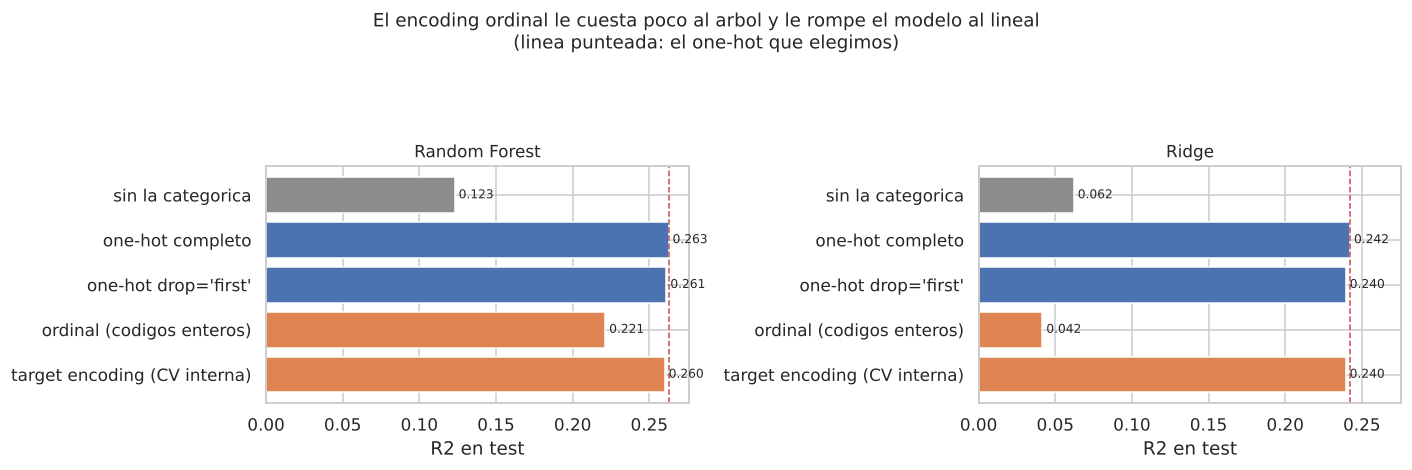

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8), sharex=True)
for a, mod in zip(ax, ["Random Forest", "Ridge"]):
    d = encoding.loc[mod].iloc[::-1]
    colores = ["#8C8C8C" if i == "sin la categorica" else
               ("#4C72B0" if i.startswith("one-hot") else "#DD8452") for i in d.index]
    a.barh(d.index, d.R2_test, color=colores)
    a.axvline(encoding.loc[(mod, "one-hot completo"), "R2_test"], color="#C44E52",
              ls="--", lw=1)
    a.set_title(mod, fontsize=11)
    a.set_xlabel("R2 en test")
    for i, v in enumerate(d.R2_test):
        a.text(v, i, f" {v:.3f}", va="center", fontsize=8)
fig.suptitle("El encoding ordinal le cuesta poco al arbol y le rompe el modelo al lineal\n"
             "(linea punteada: el one-hot que elegimos)", fontsize=12, y=1.12)
plt.tight_layout(); plt.show()

## Lectura: el encoding importa, y le importa mucho más al modelo lineal

**Codificar la operadora aporta, y aporta bastante.** Sin la categórica, Random Forest queda en R²
0,123; con one-hot, en 0,263. Es el salto que ya habíamos visto por bloques, visto ahora desde el
encoding.

**El ordinal se comporta como anticipaba la teoría, y la diferencia entre modelos es enorme.** En
Random Forest cuesta poco (0,263 → 0,221): el árbol puede partir la variable varias veces y
reconstruir los grupos, aunque desperdicia profundidad en hacerlo. En Ridge es una catástrofe
(0,240 → **0,042**): el modelo lineal está obligado a tratar el código entero como una escala, y le
impone a las operadoras un orden que no existe. Es la demostración concreta de por qué no se usa
encoding ordinal para categóricas sin orden.

**El `drop="first"` no cambia nada material** (0,263 → 0,261 en el árbol; 0,242 → 0,240 en Ridge). Lo
mantenemos solo en los modelos lineales, donde quitar una columna evita la colinealidad perfecta
entre las indicadoras y el intercepto. En los árboles no hace falta y no lo usamos.

**El target encoding empata con one-hot usando una sola columna** en lugar de diez: R² 0,260 contra
0,263 en el árbol, con un MAE levemente mejor (10.496 contra 10.596). Con diez categorías esa economía
no vale el riesgo de filtración, y nos quedamos con one-hot. Pero el resultado es la señal de que
**para `yacimiento`, con 63 categorías, el target encoding es el camino**: con one-hot serían 63
columnas para 1.298 pozos de entrenamiento.

**Decisión: one-hot, completo en los árboles y con `drop="first"` en los lineales**, que es lo que ya
estaba en el pipeline del punto 9. Lo que agrega este punto no es un cambio de modelo: es la
verificación de que la opción por defecto era la correcta, y la medición de cuánto costaría
equivocarse.

# Parte 4: Entrenamiento y comparación de modelos

Entrenamos cuatro modelos, elegidos para cubrir familias distintas y poder comparar.

| Modelo | Familia | Por qué lo incluimos |
|---|---|---|
| Regresión lineal | lineal | el más simple e interpretable: el punto de partida obligado |
| Ridge | lineal regularizada | controla la multicolinealidad residual penalizando coeficientes grandes |
| Random Forest | ensamble de árboles (bagging) | captura no linealidades e interacciones sin que las especifiquemos |
| Histogram Gradient Boosting | ensamble de árboles (boosting) | suele ser el más preciso en datos tabulares |

# 12. Modelos lineales

La regresión lineal plantea que la producción es una suma ponderada de las variables de diseño. Es
una simplificación fuerte —en la realidad hay rendimientos decrecientes— pero tiene una ventaja
grande: cada coeficiente se lee directamente como "cuántos m³ más por cada unidad de esta variable".

**Ridge** agrega una penalización sobre el tamaño de los coeficientes. Es la herramienta indicada
cuando quedan variables parcialmente correlacionadas: en vez de darle todo el peso a una y dejar la
otra en cero de forma arbitraria, reparte el efecto de manera estable. El parámetro `alpha` controla
cuánta penalización, y lo elegimos por validación cruzada.

In [30]:
m_lineal = evaluar("Regresion lineal",
                   Pipeline([("pre", pre_lineal), ("mod", LinearRegression())]),
                   resultados)

m_ridge = evaluar("Ridge",
                  Pipeline([("pre", pre_lineal),
                            ("mod", RidgeCV(alphas=np.logspace(-3, 3, 25)))]),
                  resultados)

print(f"\nalpha elegido por validacion cruzada: "
      f"{m_ridge.named_steps['mod'].alpha_:.3f}")

Regresion lineal           test -> MAE   10,776 m3   RMSE   15,019 m3   R2  0.244
Ridge                      test -> MAE   10,814 m3   RMSE   15,059 m3   R2  0.240

alpha elegido por validacion cruzada: 3.162


# 13. Modelos de árboles

Los árboles funcionan distinto: en vez de una ecuación, van partiendo el espacio de variables en
regiones y prediciendo el promedio de cada región. Esto les permite capturar **relaciones no
lineales** y **interacciones** entre variables sin que las declaremos.

**Random Forest** entrena cientos de árboles, cada uno sobre una muestra distinta de los datos y de
las variables, y promedia. **Gradient Boosting** los entrena en cadena: cada árbol nuevo corrige los
errores del anterior.

Los hiperparámetros los fijamos para controlar el sobreajuste, que con 1.298 pozos de entrenamiento
es un riesgo real:

- `min_samples_leaf`: mínimo de pozos por hoja. Evita hojas de un pozo, que son memorización.
- `max_features`: fracción de variables que cada partición puede considerar. Fuerza diversidad.
- `max_depth` y `l2_regularization` en boosting: limitan la complejidad de cada árbol.

In [31]:
m_rf = evaluar("Random Forest",
               Pipeline([("pre", pre_arbol),
                         ("mod", RandomForestRegressor(
                             n_estimators=600, min_samples_leaf=8, max_features=0.4,
                             random_state=SEMILLA, n_jobs=-1))]),
               resultados)

m_hgb = evaluar("Gradient Boosting",
                Pipeline([("pre", pre_arbol),
                          ("mod", HistGradientBoostingRegressor(
                              max_depth=3, learning_rate=0.05, max_iter=300,
                              min_samples_leaf=30, l2_regularization=5.0,
                              max_features=0.6, random_state=SEMILLA))]),
                resultados)

Random Forest              test -> MAE   10,596 m3   RMSE   14,829 m3   R2  0.263


Gradient Boosting          test -> MAE   10,878 m3   RMSE   14,965 m3   R2  0.249


# 14. Comparación de los cuatro modelos

In [32]:
tabla = pd.DataFrame(resultados).T[["MAE_train", "MAE_test", "RMSE_train",
                                    "RMSE_test", "R2_train", "R2_test"]]
tabla["mejora_MAE_vs_ref"] = (1 - tabla.MAE_test / tabla.loc["Referencia: mediana",
                                                             "MAE_test"])
print(tabla.round(3).to_string())

                     MAE_train  MAE_test  RMSE_train  RMSE_test  R2_train  R2_test  mejora_MAE_vs_ref
Referencia: mediana     14,564    14,138      17,978     18,782    -0.001   -0.183              0.000
Regresion lineal         9,552    10,776      12,729     15,019     0.498    0.244              0.238
Ridge                    9,542    10,814      12,741     15,059     0.497    0.240              0.235
Random Forest            6,885    10,596       9,607     14,829     0.714    0.263              0.251
Gradient Boosting        7,331    10,878      10,037     14,965     0.688    0.249              0.231


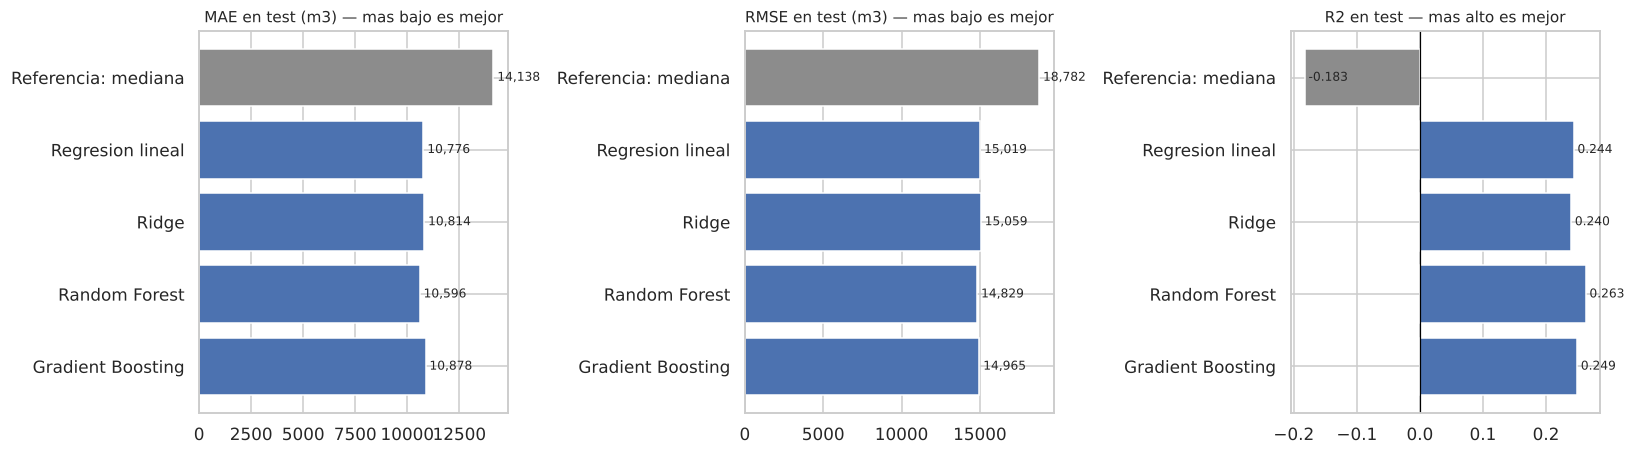

In [33]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4.3))
orden = tabla.index.tolist()
colores = ["#8C8C8C"] + ["#4C72B0"] * (len(orden) - 1)

for a, (met, titulo, mejor) in zip(ax, [
        ("MAE_test", "MAE en test (m3) — mas bajo es mejor", "min"),
        ("RMSE_test", "RMSE en test (m3) — mas bajo es mejor", "min"),
        ("R2_test", "R2 en test — mas alto es mejor", "max")]):
    valores = tabla[met]
    a.barh(orden[::-1], valores[::-1], color=colores[::-1])
    a.set_title(titulo, fontsize=10)
    if met == "R2_test":
        a.axvline(0, color="black", lw=0.8)
    for i, v in enumerate(valores[::-1]):
        a.text(v, i, f" {v:,.0f}" if met != "R2_test" else f" {v:.3f}",
               va="center", fontsize=8)
plt.tight_layout(); plt.show()

## Lectura de la tabla

**Los cuatro modelos le ganan a la referencia**, y por un margen parecido: entre 23% y 25% menos de
MAE. El mejor es **Random Forest**, con un MAE de **10.596 m³** contra los 14.138 de la referencia,
y un R² de **0,263**.

Tres cosas que vale la pena señalar:

**1. Las diferencias entre modelos son chicas.** Ridge da R² 0,240 y Random Forest 0,263. Con 619
pozos en test, esa diferencia está en el orden del ruido. En la práctica los cuatro modelos capturan
lo mismo, y eso es informativo: significa que la señal disponible en las variables de diseño es
mayormente **lineal y aditiva**. No hay interacciones complejas escondidas que solo los árboles
puedan ver.

**2. Los árboles sobreajustan mucho más.** Random Forest tiene R² 0,714 en train y 0,263 en test.
Los modelos lineales van de 0,497 a 0,240. Es el comportamiento esperado: los árboles tienen más
capacidad para memorizar, y con 1.298 pozos la aprovechan. Volvemos sobre esto en el punto 17.

**3. El RMSE es muy superior al MAE** en todos los modelos: alrededor de 14.800 contra 10.600. La
diferencia indica que hay pozos donde el error es mucho más grande que el típico. Son los extremos,
y los identificamos en el punto 21.

# Parte 5: Validación cruzada, hiperparámetros, sobreajuste y variantes

Cinco puntos sobre lo mismo: **cuánto de lo que medimos es el modelo y cuánto es la forma de
medirlo**. Primero formalizamos la validación con las herramientas de scikit-learn (puntos 15 y
16), después diagnosticamos el sobreajuste (17), comparamos los dos esquemas de partición (18) y
cerramos con la validación expansiva y las variantes que descartamos (19).

# 15. Validación cruzada con `TimeSeriesSplit`

Hasta acá evaluamos con **una sola partición**: train hasta 2023, test 2024-2025. Eso tiene un
problema conocido: el resultado depende de ese corte en particular. La validación cruzada lo resuelve
promediando varias particiones, y además permite comparar modelos **sin tocar el conjunto de test**,
que es lo que lo mantiene limpio para la evaluación final.

Pero la validación cruzada estándar —`KFold`— reparte las filas al azar, y eso es justamente lo que
el punto 8 descartó: mezclar años le deja ver al modelo pozos del mismo período con el que después se
lo evalúa.

`TimeSeriesSplit` hace lo correcto para datos con orden temporal: genera cortes **expansivos**, donde
cada fold entrena con el pasado y valida con el futuro inmediato.

```
fold 1:  [train........]  [val]
fold 2:  [train...............]  [val]
fold 3:  [train......................]  [val]
```

Hay un requisito que es fácil pasar por alto: **`TimeSeriesSplit` no mira ninguna fecha**. Parte por
posición de fila, así que asume que el DataFrame ya viene ordenado cronológicamente. Si se le pasan
las filas en el orden original, los cortes no tienen ningún significado temporal y el resultado es
indistinguible de una partición arbitraria. Ordenamos explícitamente por año de fractura antes de
usarlo.

In [34]:
# TimeSeriesSplit parte por POSICION de fila: hay que ordenar por tiempo primero.
orden_temporal = train.sort_values(["anio_fractura", "idpozo"]).index
X_train_ord = train.loc[orden_temporal, NUMERICAS + CATEGORICAS_MODELO]
y_train_ord = train.loc[orden_temporal, OBJETIVO]
anios_ord = train.loc[orden_temporal, "anio_fractura"].to_numpy()

N_FOLDS = 5
tscv = TimeSeriesSplit(n_splits=N_FOLDS)

print(f"TimeSeriesSplit({N_FOLDS}) sobre los {len(X_train_ord):,} pozos de entrenamiento:\n")
for i, (idx_tr, idx_val) in enumerate(tscv.split(X_train_ord), 1):
    print(f"  fold {i}:  train n={len(idx_tr):4d} ({anios_ord[idx_tr].min():.0f}-"
          f"{anios_ord[idx_tr].max():.0f})   ->   validacion n={len(idx_val):3d} "
          f"({anios_ord[idx_val].min():.0f}-{anios_ord[idx_val].max():.0f})")
print(f"\nEl conjunto de test (2024-2025, {len(test)} pozos) no participa: queda intacto.")

TimeSeriesSplit(5) sobre los 1,298 pozos de entrenamiento:

  fold 1:  train n= 218 (2011-2017)   ->   validacion n=216 (2017-2019)
  fold 2:  train n= 434 (2011-2019)   ->   validacion n=216 (2019-2021)
  fold 3:  train n= 650 (2011-2021)   ->   validacion n=216 (2021-2022)
  fold 4:  train n= 866 (2011-2022)   ->   validacion n=216 (2022-2023)
  fold 5:  train n=1082 (2011-2023)   ->   validacion n=216 (2023-2023)

El conjunto de test (2024-2025, 619 pozos) no participa: queda intacto.


Una limitación que conviene decir antes de leer los resultados: **los cortes caen en mitad de un año**.
`TimeSeriesSplit` divide en bloques de igual cantidad de filas, no por año calendario, así que el fold
1 valida sobre pozos de 2017 a 2019 y el fold 5 sobre pozos de 2023. Dentro de un mismo año el orden
entre pozos es arbitrario, así que algunos folds mezclan pozos del mismo año entre train y validación.

Es una aproximación aceptable, y la versión con límites exactos por año es la validación expansiva que
hacemos a mano en el punto 19. Las dos miden lo mismo; esta usa la herramienta estándar y es la que
se puede pasar directamente a `GridSearchCV`.

Ahora la comparación que importa: el mismo modelo, los mismos datos, dos esquemas de validación.

In [35]:
# El mismo modelo evaluado con validacion temporal y con validacion aleatoria.
# Importante: KFold se corre sobre el orden original, TimeSeriesSplit sobre el ordenado.
def pipeline_rf():
    return Pipeline([("pre", ColumnTransformer([
                          ("num", SimpleImputer(strategy="median"), NUMERICAS),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS_MODELO)])),
                     ("mod", RandomForestRegressor(n_estimators=600, min_samples_leaf=8,
                                                   max_features=0.4, random_state=SEMILLA,
                                                   n_jobs=-1))])

esquemas_cv = {
    "TimeSeriesSplit (temporal)": (TimeSeriesSplit(n_splits=N_FOLDS), X_train_ord, y_train_ord),
    "KFold (aleatoria)": (KFold(n_splits=N_FOLDS, shuffle=True, random_state=SEMILLA),
                          X_train, y_train)}

cv_r2, filas = {}, []
for etiqueta, (cv, X_, y_) in esquemas_cv.items():
    r2s = cross_val_score(pipeline_rf(), X_, y_, cv=cv, scoring="r2", n_jobs=-1)
    maes = -cross_val_score(pipeline_rf(), X_, y_, cv=cv,
                            scoring="neg_mean_absolute_error", n_jobs=-1)
    cv_r2[etiqueta] = r2s
    filas.append({"esquema": etiqueta, "R2_medio": r2s.mean(), "R2_desvio": r2s.std(),
                  "R2_min": r2s.min(), "R2_max": r2s.max(), "MAE_medio": maes.mean()})

comp_cv = pd.DataFrame(filas).set_index("esquema")
print(comp_cv.to_string(float_format=f3))
print("\nR2 fold por fold:")
for etiqueta, r2s in cv_r2.items():
    print(f"  {etiqueta:28s} {np.round(r2s, 3)}")
print(f"\nCociente entre esquemas: "
      f"{cv_r2['KFold (aleatoria)'].mean() / cv_r2['TimeSeriesSplit (temporal)'].mean():.2f}x")

                            R2_medio  R2_desvio  R2_min  R2_max  MAE_medio
esquema                                                                   
TimeSeriesSplit (temporal)     0.171      0.116   0.017   0.335     11,765
KFold (aleatoria)              0.546      0.044   0.473   0.610      8,851

R2 fold por fold:
  TimeSeriesSplit (temporal)   [0.231 0.017 0.335 0.063 0.206]
  KFold (aleatoria)            [0.473 0.61  0.543 0.565 0.539]

Cociente entre esquemas: 3.20x


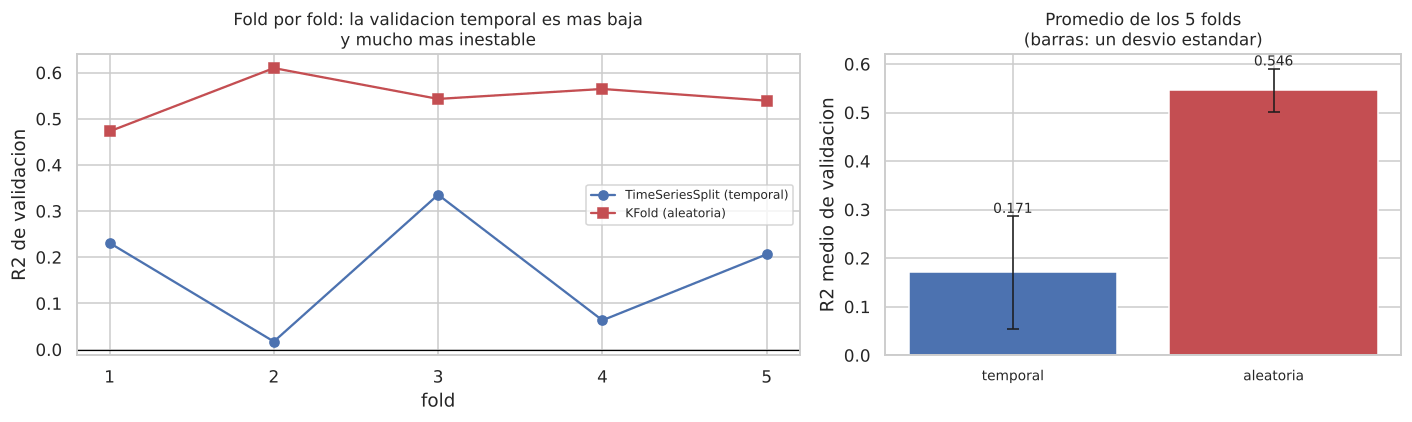

In [36]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [1.4, 1]})

x = np.arange(1, N_FOLDS + 1)
for etiqueta, color, marca in [("TimeSeriesSplit (temporal)", "#4C72B0", "o"),
                               ("KFold (aleatoria)", "#C44E52", "s")]:
    ax[0].plot(x, cv_r2[etiqueta], marker=marca, color=color, label=etiqueta)
ax[0].axhline(0, color="black", lw=0.8)
ax[0].set_xticks(x); ax[0].set_xlabel("fold"); ax[0].set_ylabel("R2 de validacion")
ax[0].set_title("Fold por fold: la validacion temporal es mas baja\ny mucho mas inestable",
                fontsize=11)
ax[0].legend(fontsize=8)

medias = [cv_r2[e].mean() for e in esquemas_cv]
desvios = [cv_r2[e].std() for e in esquemas_cv]
ax[1].bar(range(2), medias, yerr=desvios, color=["#4C72B0", "#C44E52"],
          error_kw=dict(lw=1, capsize=4))
ax[1].set_xticks(range(2)); ax[1].set_xticklabels(["temporal", "aleatoria"], fontsize=9)
ax[1].set_ylabel("R2 medio de validacion")
ax[1].set_title("Promedio de los 5 folds\n(barras: un desvio estandar)", fontsize=11)
for i, (m, d) in enumerate(zip(medias, desvios)):
    ax[1].text(i, m + d, f"{m:.3f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout(); plt.show()

## El hallazgo del punto 18, confirmado sin usar el test

Este resultado es el mismo que el del punto 18, obtenido por un camino independiente:

- **`TimeSeriesSplit`: R² 0,171** de promedio, con desvío 0,116 entre folds.
- **`KFold`: R² 0,546** de promedio, con desvío 0,044.

**La validación aleatoria da 3,2 veces más**, y acá la comparación es más limpia que en el punto 18:
todo esto se mide **dentro del conjunto de entrenamiento**, sin que el test participe. No hay forma de
atribuir la diferencia a una particularidad de los pozos de 2024-2025, porque esos pozos no se usaron.

Dos cosas más que agrega este punto:

**La inestabilidad es parte del resultado.** El desvío entre folds temporales es 0,116, contra 0,044 en
los aleatorios: casi el triple. Los folds temporales van de 0,017 a 0,335. Cuando el R² depende tanto
de qué año toque predecir, reportar un único número sin su dispersión da una falsa sensación de
precisión. Es la razón por la que el 0,263 del punto 14 hay que leerlo junto con el rango 0,11-0,29 del
punto 19.

**El R² de validación cruzada es más bajo que el de test** (0,171 contra 0,263), y no es contradictorio:
los folds de `TimeSeriesSplit` entrenan con entre 218 y 1.082 pozos, bastante menos que los 1.298 del
modelo final. Un modelo con menos datos rinde menos. La validación cruzada sirve para **comparar entre
sí** configuraciones, no para estimar el rendimiento final —para eso está el test.

# 16. Optimización de hiperparámetros con `GridSearchCV`

En los puntos 12 y 13 fijamos los hiperparámetros **a mano**, razonando sobre el sobreajuste:
`min_samples_leaf=8` para que ninguna hoja memorice un pozo, `max_features=0,4` para forzar diversidad
entre árboles. El razonamiento es defendible, pero es un razonamiento, no una medición.

Ahora lo medimos. `GridSearchCV` prueba todas las combinaciones de una grilla, evaluando cada una con
validación cruzada, y se queda con la mejor. Usamos **el `TimeSeriesSplit` del punto 15**, no `KFold`:
optimizar contra una validación aleatoria elegiría los hiperparámetros que mejor funcionan cuando se
puede ver el futuro, que no es el problema que tenemos.

La grilla recorre los cuatro parámetros que controlan la capacidad del bosque:

| Parámetro | Valores | Qué controla |
|---|---|---|
| `n_estimators` | 300, 600 | cuántos árboles se promedian |
| `min_samples_leaf` | 2, 4, 8, 16, 32 | cuán chicas pueden ser las hojas |
| `max_features` | 0,3 · 0,4 · 0,6 · 1,0 | cuántas variables ve cada partición |
| `max_depth` | sin límite, 8, 14 | cuán profundo crece cada árbol |

Son **120 combinaciones × 5 folds = 600 ajustes**. Los valores que elegimos a mano están dentro de la
grilla, así que el resultado dice directamente si acertamos.

In [37]:
# GridSearchCV con validacion temporal. El scoring es MAE: esta en m3 y es interpretable.
grilla = {"mod__n_estimators": [300, 600],
          "mod__min_samples_leaf": [2, 4, 8, 16, 32],
          "mod__max_features": [0.3, 0.4, 0.6, 1.0],
          "mod__max_depth": [None, 8, 14]}

pipe_busqueda = Pipeline([
    ("pre", ColumnTransformer([("num", SimpleImputer(strategy="median"), NUMERICAS),
                               ("cat", OneHotEncoder(handle_unknown="ignore"),
                                CATEGORICAS_MODELO)])),
    ("mod", RandomForestRegressor(random_state=SEMILLA, n_jobs=1))])

busqueda = GridSearchCV(pipe_busqueda, grilla, cv=TimeSeriesSplit(n_splits=N_FOLDS),
                        scoring="neg_mean_absolute_error", n_jobs=-1, refit=True)
busqueda.fit(X_train_ord, y_train_ord)

A_MANO = {"mod__n_estimators": 600, "mod__min_samples_leaf": 8,
          "mod__max_features": 0.4, "mod__max_depth": None}
res_cv = pd.DataFrame(busqueda.cv_results_)
i_mano = next(i for i, p in enumerate(busqueda.cv_results_["params"])
              if all(p[k] == v for k, v in A_MANO.items()))

print(f"Combinaciones evaluadas: {len(res_cv)}  ({len(res_cv) * N_FOLDS} ajustes)\n")
print("Mejor combinacion segun la validacion temporal:")
for k, v in busqueda.best_params_.items():
    print(f"  {k.replace('mod__', ''):20s} {v}")
print(f"\nMAE de validacion cruzada:")
print(f"  mejor de la grilla        {-busqueda.best_score_:>9,.0f} m3")
print(f"  valores elegidos a mano   {-res_cv.mean_test_score.iloc[i_mano]:>9,.0f} m3   "
      f"(puesto {int(res_cv.rank_test_score.iloc[i_mano])} de {len(res_cv)})")
print(f"  diferencia                {-busqueda.best_score_ + res_cv.mean_test_score.iloc[i_mano]:>9,.0f} m3   "
      f"({(res_cv.mean_test_score.iloc[i_mano] / busqueda.best_score_ - 1):+.1%})")

Combinaciones evaluadas: 120  (600 ajustes)

Mejor combinacion segun la validacion temporal:
  max_depth            8
  max_features         0.3
  min_samples_leaf     2
  n_estimators         600

MAE de validacion cruzada:
  mejor de la grilla           11,432 m3
  valores elegidos a mano      11,765 m3   (puesto 49 de 120)
  diferencia                     -333 m3   (+2.9%)


In [38]:
# Las cinco mejores combinaciones, para ver si el optimo es una meseta o un pico.
mejores = res_cv.nsmallest(5, "rank_test_score").copy()
mejores["MAE_cv"] = -mejores.mean_test_score
mejores["desvio_cv"] = mejores.std_test_score
print("Las 5 mejores combinaciones de la grilla:")
print(mejores[["param_mod__n_estimators", "param_mod__min_samples_leaf",
               "param_mod__max_features", "param_mod__max_depth",
               "MAE_cv", "desvio_cv"]]
      .to_string(index=False, float_format=lambda x: f"{x:,.1f}"))

print("\nY ahora lo que importa: ¿la mejora de la grilla se traslada al test?")
# Se reentrena en el ORDEN ORIGINAL de las filas, que es el que usa todo el resto del
# notebook: asi el modelo "a mano" reproduce exactamente el 0,263 del punto 14 y la
# comparacion mide la grilla, no el orden de las filas.
en_test = {}
for etiqueta, estimador in [("a mano (el del punto 13)", pipeline_rf()),
                            ("optimizado por GridSearchCV", clone(busqueda.best_estimator_))]:
    pred = clone(estimador).fit(X_train, y_train).predict(X_test)
    r2s = cross_val_score(clone(estimador), X_train_ord, y_train_ord,
                          cv=TimeSeriesSplit(n_splits=N_FOLDS), scoring="r2", n_jobs=-1)
    en_test[etiqueta] = {"R2_cv_temporal": r2s.mean(),
                         "R2_test": r2_score(y_test, pred),
                         "MAE_test": mean_absolute_error(y_test, pred)}
print()
print(pd.DataFrame(en_test).T.to_string(float_format=f3))

# El MISMO modelo optimizado, reajustado sobre las filas ordenadas por año en lugar del
# orden original. No cambia ni un hiperparametro: solo el orden en que ve las filas, que
# altera el muestreo bootstrap del bosque.
pred_ord = busqueda.best_estimator_.predict(X_test)
print(f"\nEl mismo optimizado, reajustado con las filas ordenadas por año:")
print(f"  R2_test {r2_score(y_test, pred_ord):.3f}   "
      f"MAE_test {mean_absolute_error(y_test, pred_ord):,.0f} m3")
print(f"  es decir {abs(r2_score(y_test, pred_ord) - en_test['optimizado por GridSearchCV']['R2_test']):.3f} "
      f"de R2 solo por el orden de las filas")

Las 5 mejores combinaciones de la grilla:
 param_mod__n_estimators  param_mod__min_samples_leaf  param_mod__max_features param_mod__max_depth   MAE_cv  desvio_cv
                     600                            2                      0.3                    8 11,431.8      965.9
                     300                            2                      0.3                    8 11,437.8      960.1
                     600                            2                      0.4                    8 11,451.2    1,090.7
                     600                            2                      0.3                 None 11,470.3      991.3
                     300                            2                      0.4                    8 11,471.1    1,145.0

Y ahora lo que importa: ¿la mejora de la grilla se traslada al test?



                             R2_cv_temporal  R2_test  MAE_test
a mano (el del punto 13)              0.171    0.263    10,596
optimizado por GridSearchCV           0.221    0.256    10,659

El mismo optimizado, reajustado con las filas ordenadas por año:
  R2_test 0.260   MAE_test 10,656 m3
  es decir 0.004 de R2 solo por el orden de las filas


## La optimización mejora la validación cruzada y no mejora el test

El resultado es el que anticipábamos en las conclusiones de la Pre-entrega 3, y vale la pena que quede
medido en lugar de supuesto.

**En validación cruzada, la grilla gana.** La mejor combinación (`max_depth=8`, `max_features=0,3`,
`min_samples_leaf=2`, `n_estimators=600`) da un MAE de **11.432 m³** contra los **11.765** de los
valores elegidos a mano: una mejora de 333 m³, el **2,9%**. Nuestros valores quedaron en el **puesto 49
de 120**: ni cerca del óptimo, ni en la cola.

**En test, la mejora desaparece.** El modelo optimizado da MAE 10.659 y R² 0,256, contra 10.596 y 0,263
del modelo a mano. Es decir: **levemente peor**. La ganancia de 333 m³ en validación cruzada no se
tradujo en nada.

Y hay un detalle que conviene mirar antes de sacar conclusiones de ese 0,256. El mismo modelo
optimizado, con los mismos hiperparámetros y los mismos datos, da **0,260 si se lo reentrena con las
filas ordenadas por año** en lugar del orden original del DataFrame. El orden de las filas cambia el
muestreo bootstrap del bosque, y mueve el R² en 0,004 sin que haya cambiado nada que tenga
significado. Eso ya es del orden de la diferencia que estamos tratando de interpretar.

Dos lecturas, y la segunda es la importante:

**Las cinco mejores combinaciones están dentro de 40 m³ entre sí**, sobre un MAE de 11.400 y con un
desvío entre folds de unos 1.000 m³: el desvío es veinticinco veces el rango que separa a las cinco
primeras. No hay un pico: hay una **meseta**. Cuando el óptimo es una meseta mucho más angosta que el
ruido de la medición, "el mejor" de la grilla es en buena medida el que tuvo suerte en esos cinco
folds.

Para afirmar eso hay que cuantificar el ruido, y se puede hacer de forma directa: entrenar el mismo
modelo, con los mismos hiperparámetros y los mismos datos, cambiando solo la semilla del bosque.

In [39]:
# El piso de ruido: lo que se mueve la metrica sin cambiar nada mas que la semilla.
r2s_semilla, maes_semilla = [], []
for semilla in range(15):
    p = Pipeline([("pre", ColumnTransformer([
                       ("num", SimpleImputer(strategy="median"), NUMERICAS),
                       ("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAS_MODELO)])),
                  ("mod", RandomForestRegressor(n_estimators=600, min_samples_leaf=8,
                                                max_features=0.4, random_state=semilla,
                                                n_jobs=-1))]).fit(X_train, y_train)
    pred = p.predict(X_test)
    r2s_semilla.append(r2_score(y_test, pred))
    maes_semilla.append(mean_absolute_error(y_test, pred))

print("Mismo modelo, mismos datos, 15 semillas distintas del bosque:")
print(f"  R2 test   media {np.mean(r2s_semilla):.3f}   desvio {np.std(r2s_semilla):.4f}   "
      f"rango {min(r2s_semilla):.3f} - {max(r2s_semilla):.3f}")
print(f"  MAE test  media {np.mean(maes_semilla):,.0f}   desvio {np.std(maes_semilla):,.0f}   "
      f"rango {min(maes_semilla):,.0f} - {max(maes_semilla):,.0f}")
dif_opt = abs(en_test["a mano (el del punto 13)"]["R2_test"]
              - en_test["optimizado por GridSearchCV"]["R2_test"])
print(f"\nDiferencia de R2 entre el modelo a mano y el optimizado:  {dif_opt:.4f}")
print(f"Desvio del R2 por cambiar solo la semilla:               "
      f"{np.std(r2s_semilla):.4f}   ({dif_opt / np.std(r2s_semilla):.1f} desvios)")
print(f"\nEl R2 del optimizado ({en_test['optimizado por GridSearchCV']['R2_test']:.3f}) cae "
      f"{'DENTRO' if min(r2s_semilla) <= en_test['optimizado por GridSearchCV']['R2_test'] <= max(r2s_semilla) else 'FUERA'}"
      f" del rango que cubren las 15 semillas del modelo a mano.")

Mismo modelo, mismos datos, 15 semillas distintas del bosque:
  R2 test   media 0.258   desvio 0.0034   rango 0.252 - 0.264
  MAE test  media 10,641   desvio 36   rango 10,575 - 10,699

Diferencia de R2 entre el modelo a mano y el optimizado:  0.0063
Desvio del R2 por cambiar solo la semilla:               0.0034   (1.9 desvios)

El R2 del optimizado (0.256) cae DENTRO del rango que cubren las 15 semillas del modelo a mano.


In [40]:
# RandomizedSearchCV: un espacio mas amplio y continuo, con la misma validacion temporal.
espacio = {"mod__n_estimators": randint(200, 900),
           "mod__min_samples_leaf": randint(1, 40),
           "mod__max_features": uniform(0.2, 0.8),
           "mod__max_depth": [None, 6, 8, 10, 14, 20],
           "mod__min_samples_split": randint(2, 20)}

aleatoria = RandomizedSearchCV(pipe_busqueda, espacio, n_iter=60,
                               cv=TimeSeriesSplit(n_splits=N_FOLDS),
                               scoring="neg_mean_absolute_error",
                               random_state=SEMILLA, n_jobs=-1, refit=True)
aleatoria.fit(X_train_ord, y_train_ord)

pred_al = clone(aleatoria.best_estimator_).fit(X_train, y_train).predict(X_test)
print(f"RandomizedSearchCV: 60 sorteos x {N_FOLDS} folds = {60 * N_FOLDS} ajustes\n")
print("Mejor combinacion:")
for k, v in aleatoria.best_params_.items():
    print(f"  {k.replace('mod__', ''):20s} "
          f"{round(v, 3) if isinstance(v, float) else v}")
print(f"\nMAE de validacion cruzada: {-aleatoria.best_score_:,.0f} m3")
print(f"En test: MAE {mean_absolute_error(y_test, pred_al):,.0f} m3   "
      f"R2 {r2_score(y_test, pred_al):.3f}")

resumen_busqueda = pd.DataFrame([
    {"modelo": "a mano (punto 13)", "MAE_cv": -res_cv.mean_test_score.iloc[i_mano],
     **{k: v for k, v in en_test["a mano (el del punto 13)"].items() if k != "R2_cv_temporal"}},
    {"modelo": "GridSearchCV", "MAE_cv": -busqueda.best_score_,
     **{k: v for k, v in en_test["optimizado por GridSearchCV"].items()
        if k != "R2_cv_temporal"}},
    {"modelo": "RandomizedSearchCV", "MAE_cv": -aleatoria.best_score_,
     "R2_test": r2_score(y_test, pred_al),
     "MAE_test": mean_absolute_error(y_test, pred_al)},
]).set_index("modelo")[["MAE_cv", "MAE_test", "R2_test"]]
print()
print(resumen_busqueda.to_string(float_format=f3))

RandomizedSearchCV: 60 sorteos x 5 folds = 300 ajustes

Mejor combinacion:
  max_depth            None
  max_features         0.392
  min_samples_leaf     2
  min_samples_split    13
  n_estimators         871

MAE de validacion cruzada: 11,517 m3
En test: MAE 10,554 m3   R2 0.255

                    MAE_cv  MAE_test  R2_test
modelo                                       
a mano (punto 13)   11,765    10,596    0.263
GridSearchCV        11,432    10,659    0.256
RandomizedSearchCV  11,517    10,554    0.255


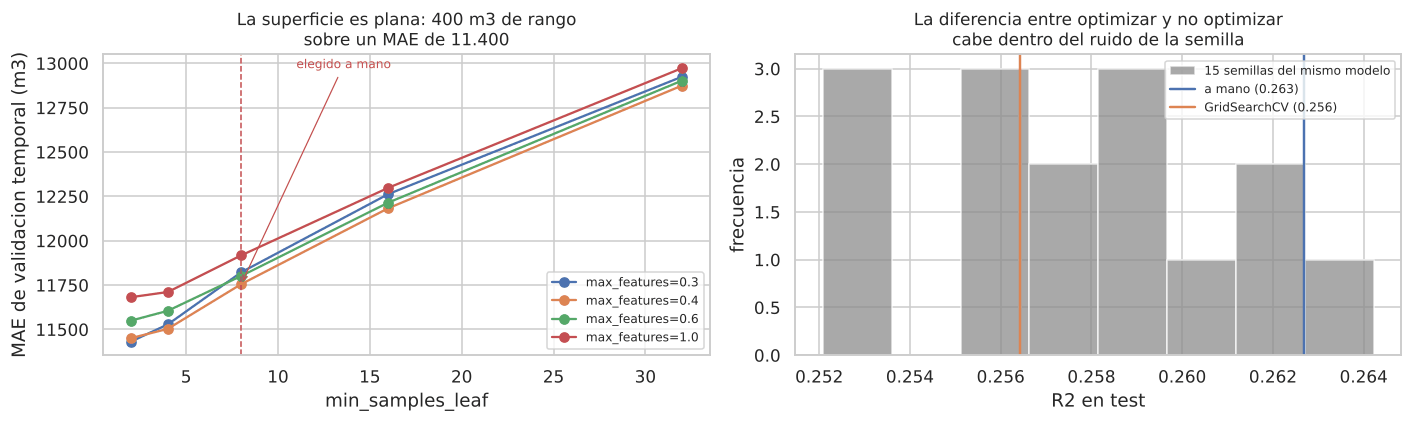

In [41]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))

# Como se mueve el MAE de CV con los dos parametros que mas importan.
pivot = (res_cv.assign(MAE_cv=-res_cv.mean_test_score)
         .groupby(["param_mod__min_samples_leaf", "param_mod__max_features"])
         .MAE_cv.min().unstack())
for columna in pivot.columns:
    ax[0].plot(pivot.index, pivot[columna], marker="o", label=f"max_features={columna}")
ax[0].axvline(8, color="#C44E52", ls="--", lw=1)
ax[0].annotate("elegido a mano", xy=(8, pivot.loc[8].min()), xytext=(11, pivot.max().max()),
               fontsize=8, color="#C44E52",
               arrowprops=dict(arrowstyle="->", color="#C44E52", lw=0.8))
ax[0].set_xlabel("min_samples_leaf"); ax[0].set_ylabel("MAE de validacion temporal (m3)")
ax[0].set_title("La superficie es plana: 400 m3 de rango\nsobre un MAE de 11.400", fontsize=11)
ax[0].legend(fontsize=8)

# El piso de ruido contra la ganancia de la optimizacion.
ax[1].hist(r2s_semilla, bins=8, color="#8C8C8C", alpha=0.75,
           label="15 semillas del mismo modelo")
r2_mano = resumen_busqueda.loc["a mano (punto 13)", "R2_test"]
ax[1].axvline(r2_mano, color="#4C72B0", lw=1.6, label=f"a mano ({r2_mano:.3f})")
ax[1].axvline(resumen_busqueda.loc["GridSearchCV", "R2_test"], color="#DD8452", lw=1.6,
              label=f"GridSearchCV ({resumen_busqueda.loc['GridSearchCV', 'R2_test']:.3f})")
ax[1].set_xlabel("R2 en test"); ax[1].set_ylabel("frecuencia")
ax[1].set_title("La diferencia entre optimizar y no optimizar\ncabe dentro del ruido de la semilla",
                fontsize=11)
ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

## Lectura y decisión

**Cambiar la semilla del bosque mueve el R² de test con un desvío de 0,003, en un rango de 0,252 a
0,264.** El R² del modelo optimizado, 0,256, **cae dentro de ese rango**: está a 1,9 desvíos del
modelo a mano, es decir dentro de lo que se mueve el mismo modelo sin que nada cambie. Sumado al
0,004 que mueve el solo orden de las filas, la conclusión es directa: **la optimización de
hiperparámetros movió la métrica en el mismo orden en que la mueven detalles sin significado**.

`RandomizedSearchCV`, explorando un espacio continuo y más amplio con 60 sorteos, lo confirma por otro
lado: MAE de validación cruzada 11.517 —peor que la grilla— y en test MAE 10.554 con R² 0,255. Es el
**mejor MAE de los tres** (42 m³ por debajo del modelo a mano) y a la vez el **peor R²**. Cuando el
ordenamiento entre las tres búsquedas se da vuelta según qué métrica se mire, ese ordenamiento no es
información.

**Decisión: mantenemos los hiperparámetros elegidos a mano**, y el modelo del punto 14 sigue siendo el
modelo del notebook. Las razones:

1. **La ganancia no existe donde importa.** 2,9% de mejora en validación cruzada, 0% en test.
2. **El óptimo es una meseta.** Las cinco mejores combinaciones están dentro de 40 m³, y el gráfico de
   la izquierda muestra que todo el rango de `min_samples_leaf` cubre unos 400 m³ sobre un MAE de
   11.400: un 3,5%.
3. **Los valores a mano son defendibles y están en la meseta.** Puesto 49 de 120 con una diferencia de
   2,9% respecto del primero.
4. **El óptimo de la grilla apunta en una dirección sospechosa.** Elige `min_samples_leaf=2`, es decir
   hojas de dos pozos, que es más capacidad de memorizar, no menos. En un problema donde ya medimos
   una brecha train-test de 0,45, aceptar eso porque mejora un 2,9% la validación cruzada es optimizar
   contra el ruido.

**Lo que este punto agrega al trabajo no es un modelo mejor: es la verificación de que no había uno
mejor por encontrar.** Eso cambia el estado de la afirmación "las diferencias son del orden del ruido"
—que hasta acá era una conjetura— por una medición concreta: el ruido de la métrica es 0,003 de R², y
la mejor de 120 combinaciones de la grilla no logra salir de esa franja en test.

# 17. Diagnóstico de sobreajuste

El sobreajuste es la distancia entre lo que el modelo logra con los datos que ya vio y lo que logra
con datos nuevos. Lo miramos lado a lado.

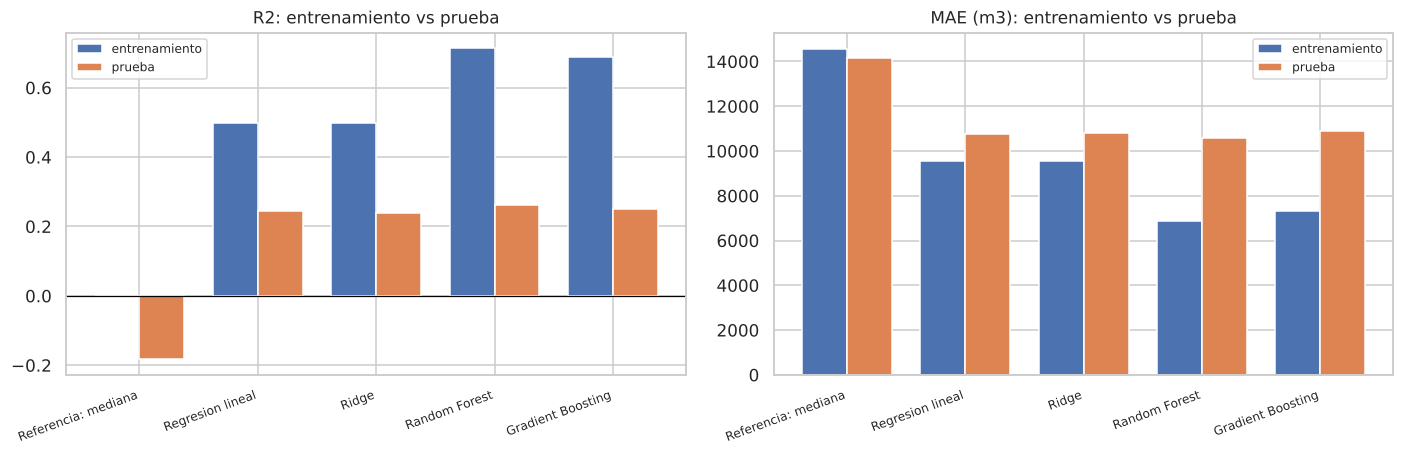

                     R2_train  R2_test  brecha_R2  MAE_test/MAE_train
Referencia: mediana    -0.001   -0.183      0.182               0.971
Regresion lineal        0.498    0.244      0.254               1.128
Ridge                   0.497    0.240      0.258               1.133
Random Forest           0.714    0.263      0.451               1.539
Gradient Boosting       0.688    0.249      0.439               1.484


In [42]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(tabla))
ancho = 0.38

for a, (met, titulo, fmt) in zip(ax, [
        ("R2", "R2: entrenamiento vs prueba", "{:.2f}"),
        ("MAE", "MAE (m3): entrenamiento vs prueba", "{:,.0f}")]):
    a.bar(x - ancho/2, tabla[f"{met}_train"], ancho, label="entrenamiento",
          color="#4C72B0")
    a.bar(x + ancho/2, tabla[f"{met}_test"], ancho, label="prueba",
          color="#DD8452")
    a.set_xticks(x); a.set_xticklabels(tabla.index, rotation=20, ha="right", fontsize=8)
    a.set_title(titulo, fontsize=11); a.legend(fontsize=8)
    if met == "R2":
        a.axhline(0, color="black", lw=0.8)

plt.tight_layout(); plt.show()

brecha = pd.DataFrame({
    "R2_train": tabla.R2_train, "R2_test": tabla.R2_test,
    "brecha_R2": tabla.R2_train - tabla.R2_test,
    "MAE_test/MAE_train": tabla.MAE_test / tabla.MAE_train})
print(brecha.round(3).to_string())

La brecha es clara y ordenada por capacidad del modelo:

| Modelo | R² train | R² test | Brecha |
|---|---|---|---|
| Regresión lineal | 0,498 | 0,244 | 0,254 |
| Ridge | 0,497 | 0,240 | 0,258 |
| Random Forest | 0,714 | 0,263 | 0,451 |
| Gradient Boosting | 0,688 | 0,249 | 0,439 |

Los árboles duplican la brecha de los lineales sin mejorar el resultado en test. Ya habíamos puesto
`min_samples_leaf=8` y `max_features=0,4` justamente para contenerlo; con parámetros más laxos la
brecha era todavía mayor (R² train de 0,83) y el test **empeoraba**.

Pero hay algo importante: **una parte de esta brecha no es sobreajuste.** Es el desplazamiento
temporal. Los modelos lineales también tienen una brecha de 0,25, y un modelo lineal con nueve
variables y 1.298 observaciones no tiene capacidad real de memorizar. Esa brecha viene de que train
y test son poblaciones distintas.

Para separar las dos cosas —cuánto es memorización y cuánto es cambio de época— hace falta la
comparación del punto siguiente.

# 18. El hallazgo: partición temporal contra partición aleatoria

Esta es la comparación más informativa del notebook. Entrenamos exactamente los mismos modelos,
con las mismas variables y los mismos hiperparámetros, cambiando **solo la forma de partir los
datos**: aleatoria en vez de temporal, con la misma proporción de test.

Una partición aleatoria depende de la semilla: con 619 pozos de test, dos semillas distintas pueden
dar R² apreciablemente distintos. Para que la comparación no dependa de un sorteo afortunado,
**la repetimos con diez semillas y promediamos**, reportando también el rango.

In [43]:
definiciones = {
    "Ridge": (RidgeCV(alphas=np.logspace(-3, 3, 25)), pre_lineal),
    "Random Forest": (RandomForestRegressor(n_estimators=600, min_samples_leaf=8,
                      max_features=0.4, random_state=SEMILLA, n_jobs=-1), pre_arbol),
    "Gradient Boosting": (HistGradientBoostingRegressor(max_depth=3, learning_rate=0.05,
                          max_iter=300, min_samples_leaf=30, l2_regularization=5.0,
                          max_features=0.6, random_state=SEMILLA), pre_arbol)}

PROPORCION_TEST = len(test) / len(modelado)
filas = []

for nombre, (mod, pre) in definiciones.items():
    r2s, maes = [], []
    for semilla in range(10):
        tr_al, te_al = train_test_split(modelado, test_size=PROPORCION_TEST,
                                        random_state=semilla)
        p = Pipeline([("pre", pre), ("mod", mod)]).fit(
            tr_al[NUMERICAS + CATEGORICAS_MODELO], tr_al[OBJETIVO])
        m_al = metricas(te_al[OBJETIVO],
                        p.predict(te_al[NUMERICAS + CATEGORICAS_MODELO]))
        r2s.append(m_al["R2"]); maes.append(m_al["MAE"])
    filas.append({"modelo": nombre,
                  "R2_temporal": tabla.loc[nombre, "R2_test"],
                  "R2_aleatorio": np.mean(r2s),
                  "R2_al_min": min(r2s), "R2_al_max": max(r2s),
                  "MAE_temporal": tabla.loc[nombre, "MAE_test"],
                  "MAE_aleatorio": np.mean(maes)})

comp = pd.DataFrame(filas).set_index("modelo")
comp["sobreestimacion_R2"] = comp.R2_aleatorio / comp.R2_temporal
print(comp.round(3).to_string())
print("\n(R2_aleatorio es el promedio de 10 semillas; min y max dan el rango)")

                   R2_temporal  R2_aleatorio  R2_al_min  R2_al_max  MAE_temporal  MAE_aleatorio  sobreestimacion_R2
modelo                                                                                                             
Ridge                    0.240         0.454      0.394      0.483        10,814          9,837               1.895
Random Forest            0.263         0.520      0.490      0.545        10,596          9,025               1.980
Gradient Boosting        0.249         0.511      0.484      0.536        10,878          9,146               2.052

(R2_aleatorio es el promedio de 10 semillas; min y max dan el rango)


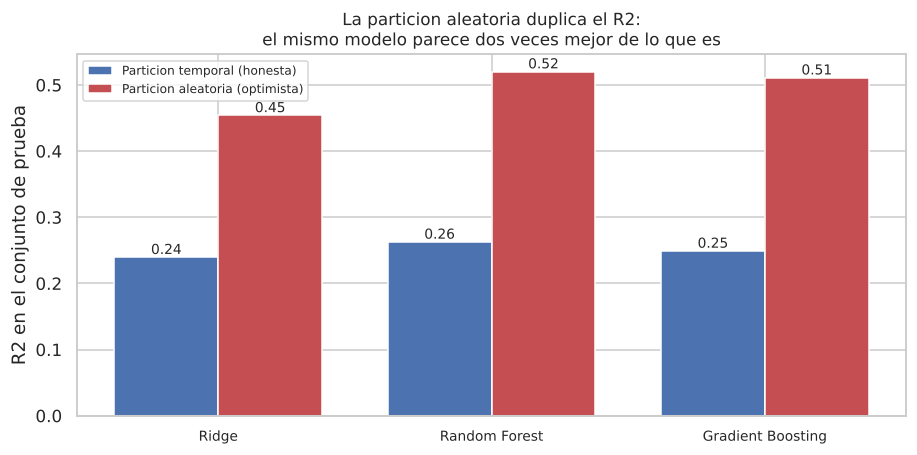

In [44]:
fig, ax = plt.subplots(figsize=(8.5, 4.3))
x = np.arange(len(comp)); ancho = 0.38
ax.bar(x - ancho/2, comp.R2_temporal, ancho, label="Particion temporal (honesta)",
       color="#4C72B0")
ax.bar(x + ancho/2, comp.R2_aleatorio, ancho, label="Particion aleatoria (optimista)",
       color="#C44E52")
for i, (t, a) in enumerate(zip(comp.R2_temporal, comp.R2_aleatorio)):
    ax.text(i - ancho/2, t, f"{t:.2f}", ha="center", va="bottom", fontsize=9)
    ax.text(i + ancho/2, a, f"{a:.2f}", ha="center", va="bottom", fontsize=9)
ax.set_xticks(x); ax.set_xticklabels(comp.index, fontsize=9)
ax.set_ylabel("R2 en el conjunto de prueba")
ax.set_title("La particion aleatoria duplica el R2:\nel mismo modelo parece "
             "dos veces mejor de lo que es", fontsize=11)
ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

## Qué significa esto

Con partición aleatoria, Random Forest da **R² 0,520** (promedio de diez semillas, rango 0,490 a
0,545). Con partición temporal, **0,263**. Es el mismo modelo, las mismas variables, los mismos
hiperparámetros. Lo único que cambió es cómo se repartieron los pozos.

**La partición aleatoria duplica el resultado**, y lo hace en los tres modelos por igual: el factor
es 1,90 en Ridge, 1,98 en Random Forest y 2,05 en Gradient Boosting. El rango entre semillas (0,490
a 0,545 en Random Forest) no se acerca en ningún caso al 0,263 de la partición temporal, así que la
diferencia no es un artefacto del sorteo.

La razón es que al mezclar años, el modelo ve pozos de 2024 y 2025 durante el entrenamiento: aprende
cómo son los diseños modernos y cuánto producen, y después se lo evalúa sobre pozos de ese mismo
período. No tiene que extrapolar nada.

Si hubiéramos hecho la partición aleatoria sin pensarlo, habríamos reportado **R² 0,52 y un modelo
que explica más de la mitad de la producción**. Habría sido un número mucho más lindo y
completamente engañoso: al aplicarlo a los pozos que se van a fracturar el año que viene, el
rendimiento real sería la mitad.

**Esta diferencia es el aprendizaje más importante de la entrega.** La métrica no depende solo del
modelo: depende de que el esquema de validación reproduzca la forma en que el modelo se va a usar.

# 19. Validación temporal expansiva y variantes que descartamos

## ¿Es el 0,26 un resultado estable o un accidente del corte en 2024?

Un solo corte temporal puede ser mala o buena suerte. Lo repetimos avanzando el corte año por año:
entrenar con todo lo anterior y predecir el año siguiente.

In [45]:
filas = []
for corte in [2021, 2022, 2023, 2024]:
    t = modelado[modelado.anio_fractura < corte]
    v = modelado[modelado.anio_fractura == corte]
    fila = {"corte": f"train < {corte}  ->  test {corte}", "n_train": len(t),
            "n_test": len(v)}
    for nombre, (mod, pre) in definiciones.items():
        p = Pipeline([("pre", pre), ("mod", mod)]).fit(
            t[NUMERICAS + CATEGORICAS_MODELO], t[OBJETIVO])
        fila[nombre] = r2_score(v[OBJETIVO],
                                p.predict(v[NUMERICAS + CATEGORICAS_MODELO]))
    filas.append(fila)

expansiva = pd.DataFrame(filas).set_index("corte")
print(expansiva.round(3).to_string())
print(f"\nR2 promedio de Random Forest a lo largo de los cortes: "
      f"{expansiva['Random Forest'].mean():.3f}")

                             n_train  n_test  Ridge  Random Forest  Gradient Boosting
corte                                                                                
train < 2021  ->  test 2021      604     188  0.283          0.201              0.216
train < 2022  ->  test 2022      792     240  0.248          0.295              0.250
train < 2023  ->  test 2023     1032     266  0.031          0.111              0.112
train < 2024  ->  test 2024     1298     321  0.240          0.252              0.254

R2 promedio de Random Forest a lo largo de los cortes: 0.214


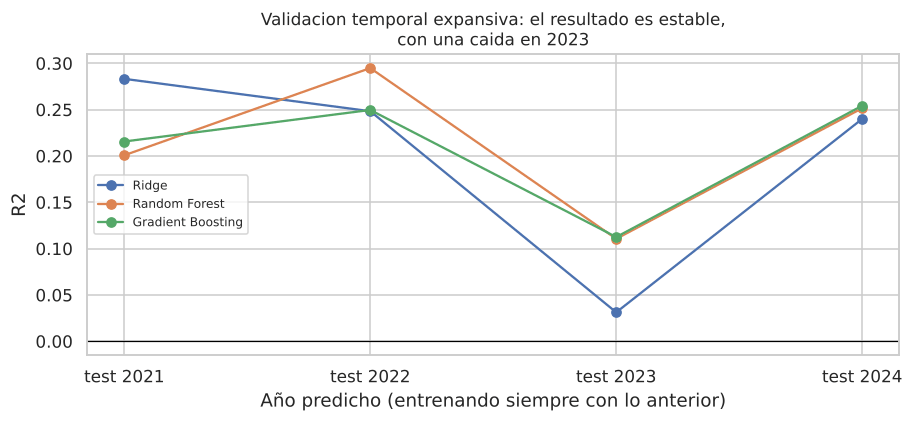

In [46]:
fig, ax = plt.subplots(figsize=(8.5, 4))
for nombre in definiciones:
    ax.plot(range(len(expansiva)), expansiva[nombre], marker="o", label=nombre)
ax.set_xticks(range(len(expansiva)))
ax.set_xticklabels([c.split("->")[1].strip() for c in expansiva.index])
ax.set_xlabel("Año predicho (entrenando siempre con lo anterior)")
ax.set_ylabel("R2")
ax.set_title("Validacion temporal expansiva: el resultado es estable,\ncon una caida "
             "en 2023", fontsize=11)
ax.legend(fontsize=8); ax.axhline(0, color="black", lw=0.8)
plt.tight_layout(); plt.show()

El resultado se sostiene: **R² entre 0,111 y 0,295 en los cuatro cortes**, con un promedio de 0,214
para Random Forest. El 0,26 del corte principal no es un accidente.

La excepción es **2023, donde cae a 0,11**. Es un año atípico en los datos: la producción mediana
baja a 33.005 m³ después de dos años en torno a 37.000, rompiendo la tendencia. No tenemos con
nuestros datos una explicación de por qué, y lo dejamos anotado como pregunta abierta.

## Variantes que probamos y descartamos

Tres alternativas razonables que no funcionaron. Las documentamos porque el resultado negativo
también es información, y porque son las primeras preguntas que aparecen al ver un R² de 0,26.

In [47]:
pruebas = []

# (a) Entrenar solo con pozos recientes, mas parecidos a los de test.
for desde in [2009, 2019, 2021]:
    t = modelado[(modelado.anio_fractura >= desde) & (modelado.anio_fractura < CORTE)]
    p = Pipeline([("pre", pre_arbol), ("mod", RandomForestRegressor(
        n_estimators=600, min_samples_leaf=8, max_features=0.4,
        random_state=SEMILLA, n_jobs=-1))]).fit(t[NUMERICAS + CATEGORICAS_MODELO],
                                                t[OBJETIVO])
    pruebas.append({"variante": f"(a) entrenar desde {desde}", "n_train": len(t),
                    "R2_test": r2_score(y_test, p.predict(X_test))})

# (b) Modelar la raiz cuadrada del objetivo y volver a la escala original.
p = Pipeline([("pre", pre_arbol), ("mod", RandomForestRegressor(
    n_estimators=600, min_samples_leaf=8, max_features=0.4,
    random_state=SEMILLA, n_jobs=-1))]).fit(X_train, np.sqrt(y_train))
pruebas.append({"variante": "(b) objetivo en raiz cuadrada", "n_train": len(train),
                "R2_test": r2_score(y_test, np.clip(p.predict(X_test), 0, None) ** 2)})

# (c) Agregar el año de fractura como variable.
NUM_ANIO = NUMERICAS + ["anio_fractura"]
pre_anio = ColumnTransformer([("num", SimpleImputer(strategy="median"), NUM_ANIO),
                              ("cat", OneHotEncoder(handle_unknown="ignore"),
                               CATEGORICAS_MODELO)])
p = Pipeline([("pre", pre_anio), ("mod", RandomForestRegressor(
    n_estimators=600, min_samples_leaf=8, max_features=0.4,
    random_state=SEMILLA, n_jobs=-1))]).fit(train[NUM_ANIO + CATEGORICAS_MODELO],
                                            y_train)
pruebas.append({"variante": "(c) agregar anio_fractura", "n_train": len(train),
                "R2_test": r2_score(y_test,
                                    p.predict(test[NUM_ANIO + CATEGORICAS_MODELO]))})

v = pd.DataFrame(pruebas).set_index("variante")
v["vs_modelo_base"] = v.R2_test - tabla.loc["Random Forest", "R2_test"]
print(f"Random Forest del punto 13: R2 = {tabla.loc['Random Forest','R2_test']:.3f}\n")
print(v.round(3).to_string())

Random Forest del punto 13: R2 = 0.263

                               n_train  R2_test  vs_modelo_base
variante                                                       
(a) entrenar desde 2009           1298    0.263           0.000
(a) entrenar desde 2019            937    0.264           0.001
(a) entrenar desde 2021            694    0.251          -0.011
(b) objetivo en raiz cuadrada     1298    0.270           0.007
(c) agregar anio_fractura         1298    0.285           0.023


**(a) Entrenar solo con pozos recientes: no aporta.** La intuición era que los pozos viejos, con
diseños que ya no se usan, podían estar confundiendo al modelo. Pero el R² se queda igual al recortar
desde 2019 (0,264 contra 0,263) y **baja** al recortar desde 2021 (0,251), donde ya se pierde el 47%
de los datos de entrenamiento. La homogeneidad que se gana no compensa los datos que se pierden.
**Nos quedamos con todo el histórico.**

**(b) Modelar la raíz cuadrada: mejora marginalmente** (0,270 contra 0,263). Es una mejora de 0,007,
dentro del ruido con 619 pozos de test, y a cambio pierde la interpretabilidad directa de las
métricas en m³. **No la adoptamos**, pero queda anotada como ajuste disponible.

**(c) Agregar el año de fractura: mejora en este corte, pero no lo adoptamos.** Es la variante que
más discutimos, porque el resultado va en contra de lo que esperábamos: sube el R² de 0,263 a
**0,285**, la mejora más grande de las tres.

Nuestra objeción es estructural. En el entrenamiento el año nunca pasa de 2023, así que para **todos**
los pozos de test el modelo está extrapolando a un valor que no vio nunca. Un árbol no puede
extrapolar: les asigna a los pozos de 2024 y 2025 la hoja que aprendió para 2023, que es la más
productiva, y acierta porque efectivamente son más productivos. Funciona, pero no por la razón que
parece: no está midiendo el efecto del año, está usando el año como un "este pozo es de los nuevos".

Si eso fuera un mecanismo confiable, debería aparecer también en los otros cortes temporales. Lo
verificamos.

In [48]:
filas = []
for corte in [2021, 2022, 2023, 2024]:
    t = modelado[modelado.anio_fractura < corte]
    v_ = modelado[modelado.anio_fractura == corte]
    fila = {"corte": f"test {corte}"}
    for etiqueta, num in [("sin anio", NUMERICAS), ("con anio", NUM_ANIO)]:
        pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                                 ("cat", OneHotEncoder(handle_unknown="ignore"),
                                  CATEGORICAS_MODELO)])
        p = Pipeline([("pre", pre), ("mod", RandomForestRegressor(
            n_estimators=600, min_samples_leaf=8, max_features=0.4,
            random_state=SEMILLA, n_jobs=-1))]).fit(
                t[num + CATEGORICAS_MODELO], t[OBJETIVO])
        fila[etiqueta] = r2_score(v_[OBJETIVO],
                                  p.predict(v_[num + CATEGORICAS_MODELO]))
    fila["diferencia"] = fila["con anio"] - fila["sin anio"]
    filas.append(fila)

print(pd.DataFrame(filas).set_index("corte").round(3).to_string())

           sin anio  con anio  diferencia
corte                                    
test 2021     0.201     0.247       0.047
test 2022     0.295     0.252      -0.043
test 2023     0.111     0.099      -0.011
test 2024     0.252     0.267       0.015


**No aguanta.** Agregar el año mejora en 2021 (+0,047) y en 2024 (+0,015), pero **empeora** en 2022
(−0,043) y en 2023 (−0,011). El signo cambia según el corte: la ganancia del corte principal es
suerte de ese corte, no una mejora del modelo.

**Decisión: no incluimos el año de fractura.** El criterio es que un predictor que solo funciona
extrapolando a valores que nunca vio no es confiable para un modelo que se va a aplicar justamente
sobre pozos futuros. Preferimos el modelo que explica menos pero por razones que se sostienen.

## Un control extra: ¿y si agregamos geología?

La conclusión recurrente es que falta información geológica. Probamos agregarla con lo que hay
disponible en datos abiertos: las **coordenadas y la cota** del listado de pozos de la Secretaría
de Energía, y el **área de concesión** como categórica, que es un proxy grueso de la geología.

In [49]:
ubic = leer("pozos_ubicacion.csv", low_memory=False)[
    ["idpozo", "coordenadax", "coordenaday", "cota", "profundidad"]]
ubic.loc[ubic.profundidad <= 0, "profundidad"] = np.nan  # 0 es un centinela, no un dato

geo = modelado.merge(ubic, on="idpozo", how="left")
conteo_area = geo.areapermisoconcesion.value_counts()
geo["area"] = geo.areapermisoconcesion.where(
    geo.areapermisoconcesion.map(conteo_area) >= 30, "otras")

print(f"Cobertura de coordenadas: {geo.coordenadax.notna().sum():,} de {len(geo):,} "
      f"({geo.coordenadax.notna().mean():.1%})")
print(f"Areas de concesion despues de agrupar: {geo.area.nunique()}")

GEO = ["coordenadax", "coordenaday", "cota", "profundidad"]
g_tr = geo[geo.anio_fractura < CORTE]
g_te = geo[geo.anio_fractura >= CORTE]

filas = []
for etiqueta, num, cat in [
        ("solo diseño (modelo base)", NUMERICAS, ["operadora"]),
        ("+ area de concesion", NUMERICAS, ["operadora", "area"]),
        ("+ coordenadas y cota", NUMERICAS + GEO, ["operadora"]),
        ("+ area + coordenadas", NUMERICAS + GEO, ["operadora", "area"])]:
    pre = ColumnTransformer([("num", SimpleImputer(strategy="median"), num),
                             ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])
    p = Pipeline([("pre", pre), ("mod", RandomForestRegressor(
        n_estimators=600, min_samples_leaf=8, max_features=0.4,
        random_state=SEMILLA, n_jobs=-1))]).fit(g_tr[num + cat], g_tr[OBJETIVO])
    pr_tr = p.predict(g_tr[num + cat]); pr_te = p.predict(g_te[num + cat])
    filas.append({"set de variables": etiqueta,
                  "R2_train": r2_score(g_tr[OBJETIVO], pr_tr),
                  "R2_test": r2_score(g_te[OBJETIVO], pr_te),
                  "MAE_test": mean_absolute_error(g_te[OBJETIVO], pr_te)})

print()
print(pd.DataFrame(filas).set_index("set de variables").round(3).to_string())

  pozos_ubicacion.csv              <- ../data/pozos_ubicacion.csv
Cobertura de coordenadas: 1,888 de 1,917 (98.5%)
Areas de concesion despues de agrupar: 15



                           R2_train  R2_test  MAE_test
set de variables                                      
solo diseño (modelo base)     0.714    0.263    10,596
+ area de concesion           0.755    0.260    10,695
+ coordenadas y cota          0.807    0.261    10,531
+ area + coordenadas          0.807    0.260    10,520


**No aporta nada.** El R² de test queda en 0,26 en los cuatro casos, mientras el R² de train sube de
0,71 a 0,81: la geografía solo agrega capacidad de memorizar.

El resultado no dice que la geología no importe —importa muchísimo—. Dice que **la latitud, la
longitud y la cota de boca de pozo no son la geología**. Lo que determina la productividad es la
calidad de la roca en el tramo horizontal, a tres kilómetros de profundidad: espesor de la ventana
de maduración, contenido orgánico, presión del reservorio, saturación. Nada de eso está en datos
abiertos, y la posición en superficie es un sustituto demasiado grueso.

Además, la operadora ya está capturando buena parte de ese efecto: cada operadora trabaja en áreas
definidas, así que `operadora` y `area` dicen cosas parecidas.

# Parte 6: Análisis del modelo elegido y conclusiones

# 20. Qué variables usa el modelo

**Modelo elegido: Random Forest.** Tiene el mejor MAE y el mejor R² en test, aunque la diferencia con
Ridge sea chica. Mantenemos Ridge como referencia interpretable y leemos las dos cosas en paralelo.

## Importancia por permutación

No usamos la importancia interna del Random Forest, que se calcula sobre los datos de entrenamiento
y favorece a las variables con muchos valores distintos. Usamos **importancia por permutación sobre
el conjunto de test**: se mezclan al azar los valores de una variable y se mide cuánto se degrada el
error. Si romper una variable no empeora nada, el modelo no la estaba usando.

La medimos en MAE, así que el resultado está en **metros cúbicos de error agregado**, que es
directamente interpretable.

In [50]:
imp = permutation_importance(m_rf, X_test, y_test, n_repeats=30,
                             random_state=SEMILLA,
                             scoring="neg_mean_absolute_error", n_jobs=-1)

importancia = pd.DataFrame({
    "variable": NUMERICAS + CATEGORICAS_MODELO,
    "aumento_MAE": imp.importances_mean,
    "desvio": imp.importances_std}).sort_values("aumento_MAE", ascending=False)
print(importancia.round(1).to_string(index=False))

                    variable  aumento_MAE  desvio
  longitud_rama_horizontal_m        1,629 129.400
                   operadora        1,594 164.900
             arena_por_metro      326.000  47.500
      espaciamiento_etapas_m      316.000  44.400
              agua_por_metro      183.400  36.300
      duracion_fractura_dias      159.900  49.200
            ratio_agua_arena      107.000  42.700
potencia_equipos_fractura_hp       99.100  66.000
       ratio_arena_importada        0.200   0.900
          presion_maxima_psi      -20.700  58.600


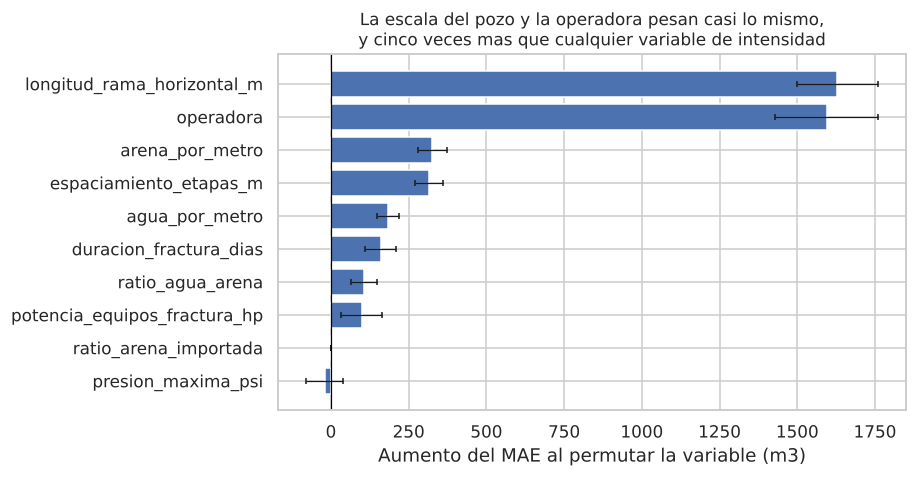

In [51]:
fig, ax = plt.subplots(figsize=(8.5, 4.5))
d = importancia.iloc[::-1]
ax.barh(d.variable, d.aumento_MAE, xerr=d.desvio, color="#4C72B0",
        error_kw=dict(lw=0.8, capsize=2))
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("Aumento del MAE al permutar la variable (m3)")
ax.set_title("La escala del pozo y la operadora pesan casi lo mismo,\ny cinco veces mas "
             "que cualquier variable de intensidad", fontsize=11)
plt.tight_layout(); plt.show()

## Lectura

**Dos variables dominan y pesan prácticamente igual**: `longitud_rama_horizontal_m` (+1.629 m³ de
error al permutarla) y `operadora` (+1.594 m³). Después hay un escalón grande: la tercera,
`arena_por_metro`, aporta +326 m³, cinco veces menos.

Los desvíos de las 30 repeticiones (129 y 165 m³) confirman que las dos primeras están
efectivamente empatadas y claramente separadas del resto.

Que la **operadora** pese tanto como la variable de diseño más importante es un resultado fuerte y
hay que leerlo con cuidado. La operadora no es una causa: no es que cambiar de empresa haga producir
más. Es un *proxy* de dos cosas que no medimos:

- **la calidad del área** que tiene cada operadora en concesión, que es geología;
- **las prácticas operativas** no documentadas en el Adjunto IV.

Dicho de otra forma: el modelo nos está diciendo que **dónde está el pozo importa tanto como cómo se
lo fracturó**, y que nuestros datos describen bien el "cómo" pero casi nada el "dónde".

Las variables de intensidad sí aportan, de forma consistente y en el orden esperado:
`arena_por_metro` (+326) y `espaciamiento_etapas_m` (+316) prácticamente empatadas, después
`agua_por_metro` (+183) y `duracion_fractura_dias` (+160).

Dos variables **no aportan nada**: `ratio_arena_importada` (+0,2 m³) y `presion_maxima_psi`
(**−20,7**, es decir que permutarla mejora apenas el error, con un desvío de 59 que la deja
indistinguible de cero). La presión máxima es en buena medida una consecuencia de la roca y del
equipo más que una decisión de diseño, y en la Pre-entrega 2 ya era la variable con más valores
imputados. `potencia_equipos_fractura_hp` queda en el límite: +99 m³ con un desvío de 66.

## Los coeficientes de Ridge: la lectura cuantitativa

El Random Forest dice qué variables usa, pero no en qué dirección. Para eso leemos los coeficientes
de Ridge. Como las variables están estandarizadas, cada coeficiente se lee como **cuántos m³ cambia
la predicción por cada desvío estándar de aumento en esa variable**, con todo lo demás constante.

In [52]:
nombres = NUMERICAS + list(m_ridge.named_steps["pre"]
                           .named_transformers_["cat"]
                           .get_feature_names_out(CATEGORICAS_MODELO))
coef = pd.Series(m_ridge.named_steps["mod"].coef_, index=nombres)

print("Variables de diseño (m3 por desvio estandar):")
print(coef[NUMERICAS].sort_values(key=abs, ascending=False).round(0).to_string())
print(f"\nRango entre operadoras: "
      f"{coef.drop(NUMERICAS).min():,.0f} a {coef.drop(NUMERICAS).max():,.0f} m3")

Variables de diseño (m3 por desvio estandar):
longitud_rama_horizontal_m        7,382
agua_por_metro                    2,609
potencia_equipos_fractura_hp      1,299
espaciamiento_etapas_m         -638.000
presion_maxima_psi              573.000
arena_por_metro                 488.000
ratio_agua_arena               -344.000
duracion_fractura_dias         -262.000
ratio_arena_importada            79.000

Rango entre operadoras: -21,751 a 11,470 m3


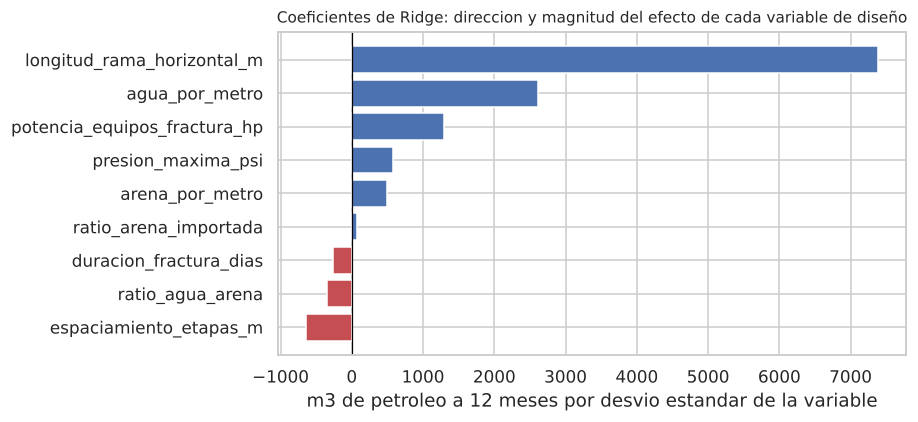

In [53]:
fig, ax = plt.subplots(figsize=(8.5, 4))
c = coef[NUMERICAS].sort_values()
ax.barh(c.index, c.values,
        color=["#C44E52" if v < 0 else "#4C72B0" for v in c.values])
ax.axvline(0, color="black", lw=0.8)
ax.set_xlabel("m3 de petroleo a 12 meses por desvio estandar de la variable")
ax.set_title("Coeficientes de Ridge: direccion y magnitud del efecto de cada variable "
             "de diseño", fontsize=10)
plt.tight_layout(); plt.show()

Los signos son coherentes con la física del problema, lo cual es una buena señal de que el modelo
no está capturando ruido:

| Variable | Coeficiente | Lectura |
|---|---|---|
| `longitud_rama_horizontal_m` | **+7.382** | un desvío más de rama (unos 900 m) son 7.400 m³ más de petróleo |
| `agua_por_metro` | +2.609 | fracturar con más fluido por metro produce más |
| `potencia_equipos_fractura_hp` | +1.299 | equipos más potentes, mejor resultado |
| `espaciamiento_etapas_m` | **−638** | más metros entre etapas es fracturar menos denso, y produce menos |
| `presion_maxima_psi` | +573 | ver la nota de abajo: el Random Forest no la usa |
| `arena_por_metro` | +488 | más arena por metro produce más, pero el efecto es chico |
| `ratio_agua_arena` | −344 | demasiada agua por tonelada de arena no ayuda |
| `duracion_fractura_dias` | −262 | una operación que se estira es una operación con problemas |
| `ratio_arena_importada` | +79 | prácticamente nulo, como en la importancia por permutación |

Dos de esas filas merecen atención porque **los dos modelos no coinciden**:

- **`presion_maxima_psi`** recibe +573 m³ por desvío en Ridge y en cambio es la única variable con
  importancia por permutación **negativa** (−20,7) en el Random Forest. No es una contradicción:
  Ridge reparte el efecto entre variables correlacionadas y le asigna parte del efecto de la escala
  del pozo, mientras que el árbol, que puede usar directamente la rama, no la necesita. Sumado a que
  es la variable con más valores imputados de la Pre-entrega 2, la lectura prudente es que **no
  aporta señal propia**.
- **`arena_por_metro`** es lo inverso: coeficiente chico en Ridge (+488, sexto lugar) pero **tercera
  variable** por importancia en el Random Forest (+326 m³ de MAE). Es la firma de un efecto **no
  lineal**: rendimientos decrecientes que una recta promedia hacia cero y un árbol sí captura.

El efecto de la **rama es de lejos el más grande**: casi tres veces el de la segunda variable. Esto
coincide con lo que se ve en la industria y con la deriva del punto 8: el principal camino por el
que subió la productividad en Vaca Muerta fue **perforar ramas más largas**.

Y el rango entre operadoras va de **−21.751 a +11.470 m³**: una brecha de 33.000 m³, del mismo orden
que la producción mediana de un pozo. Insistimos en la interpretación: eso no mide la habilidad de
cada empresa, mide sobre todo la calidad del área que le tocó.

## ¿Cuánto aporta cada bloque de variables?

Una última mirada: armamos el modelo por capas, agregando un bloque a la vez.

In [54]:
bloques = {
    "solo escala (rama)": (["longitud_rama_horizontal_m"], []),
    "+ intensidad (arena, agua, etapas)": (
        ["longitud_rama_horizontal_m", "arena_por_metro", "agua_por_metro",
         "espaciamiento_etapas_m"], []),
    "+ ratios y equipo (todo el diseño)": (NUMERICAS, []),
    "+ operadora (modelo final)": (NUMERICAS, CATEGORICAS_MODELO)}

filas = []
for etiqueta, (num, cat) in bloques.items():
    pasos = [("num", SimpleImputer(strategy="median"), num)]
    if cat:
        pasos.append(("cat", OneHotEncoder(handle_unknown="ignore"), cat))
    p = Pipeline([("pre", ColumnTransformer(pasos)),
                  ("mod", RandomForestRegressor(n_estimators=600, min_samples_leaf=8,
                   max_features=0.4, random_state=SEMILLA, n_jobs=-1))]).fit(
                       train[num + cat], y_train)
    pr = p.predict(test[num + cat])
    filas.append({"bloque": etiqueta, "variables": len(num) + len(cat),
                  "R2_test": r2_score(y_test, pr),
                  "MAE_test": mean_absolute_error(y_test, pr)})

print(pd.DataFrame(filas).set_index("bloque").round(3).to_string())

                                    variables  R2_test  MAE_test
bloque                                                          
solo escala (rama)                          1   -0.146    13,629
+ intensidad (arena, agua, etapas)          4    0.161    11,564
+ ratios y equipo (todo el diseño)          9    0.123    11,560
+ operadora (modelo final)                 10    0.263    10,596


Este cuadro tiene dos sorpresas.

**La longitud de rama sola da R² −0,146: peor que la referencia.** Es llamativo, porque es la
variable con más correlación con el objetivo (0,47) y la más importante del modelo. La explicación
es el límite de los árboles frente a la extrapolación: las ramas de test son más largas que todas las
de train, así que el árbol las mete todas en su hoja más alta y les predice el mismo valor, que le
queda corto. Con una sola variable no tiene nada que compense; en el modelo completo, el resto de
las variables corrigen.

**Agregar las variables de intensidad lleva el R² de −0,146 a 0,161.** Este es el aporte concreto del
feature engineering que hicimos en la Pre-entrega 2: las variables de intensidad no estaban en el
dataset original, las construimos nosotros, y son las que hacen que el modelo funcione. El salto más
grande en términos de aporte propio del proyecto está acá.

Después, los ratios y las variables de equipo **no agregan** (0,161 → 0,123: baja, dentro del
ruido), y la operadora sí: **0,123 → 0,263**, duplicando el R². Otra vez: la variable que más suma
es la que representa lo que no medimos.

# 21. Diagnóstico del error: dónde se equivoca el modelo

Un R² de 0,26 es un promedio, y no dice nada sobre **en qué pozos** falla. Eso es lo que define si el
modelo sirve para algo en la práctica.

In [55]:
pred_test = m_rf.predict(X_test)
residuos = y_test.values - pred_test

print(f"Produccion real media en test:     {y_test.mean():>10,.0f} m3")
print(f"Prediccion media del modelo:       {pred_test.mean():>10,.0f} m3")
print(f"Sesgo (prediccion - real):         {pred_test.mean()-y_test.mean():>+10,.0f} m3"
      f"  ({pred_test.mean()/y_test.mean()-1:+.1%})")
print(f"\nMAE:                               {mean_absolute_error(y_test, pred_test):>10,.0f} m3")
print(f"MAE como % de la produccion media: "
      f"{mean_absolute_error(y_test, pred_test)/y_test.mean():>10.1%}")
print(f"\nResiduo mediano:                   {np.median(residuos):>+10,.0f} m3")
print(f"Residuos dentro de +/- 10.000 m3:  "
      f"{(np.abs(residuos)<10_000).mean():>10.1%} de los pozos")

Produccion real media en test:         36,237 m3
Prediccion media del modelo:           38,322 m3
Sesgo (prediccion - real):             +2,085 m3  (+5.8%)

MAE:                                   10,596 m3
MAE como % de la produccion media:      29.2%

Residuo mediano:                       -3,250 m3
Residuos dentro de +/- 10.000 m3:       55.7% de los pozos


El **sesgo es chico**: el modelo predice en promedio 38.322 m³ contra 36.237 reales, un 5,8% de más.

Esto corrige una hipótesis que teníamos. Esperábamos que, entrenado solo con pozos anteriores a
2024, el modelo **subestimara** sistemáticamente los pozos nuevos, más productivos. No pasa: los
sobreestima levemente. La razón es que el modelo no predice por año, predice por diseño, y los pozos
de 2024-2025 **tienen** el diseño intensivo que el modelo asocia a alta producción. El diseño moderno
sí se refleja en la predicción.

Entonces el problema no es de calibración, es de **dispersión**: el modelo acierta el nivel promedio
y falla en distinguir entre pozos. Solo el 56% de los pozos cae dentro de ±10.000 m³.

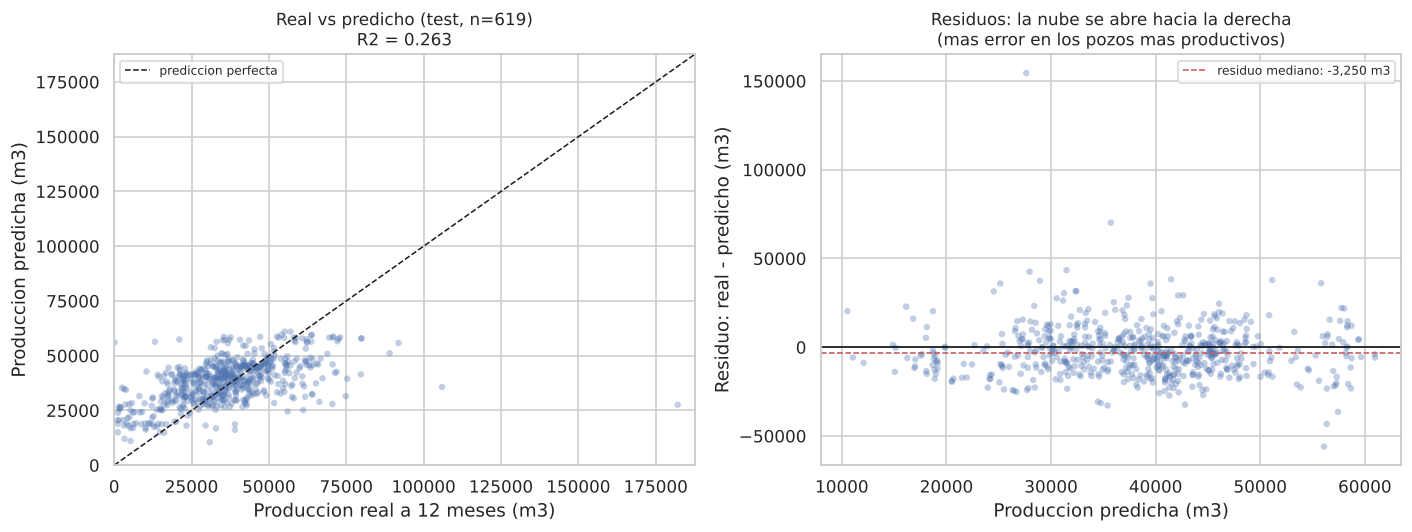

In [56]:
fig, ax = plt.subplots(1, 2, figsize=(13, 5))

lim = [0, max(y_test.max(), pred_test.max()) * 1.03]
ax[0].scatter(y_test, pred_test, alpha=0.35, s=18, color="#4C72B0",
              edgecolor="none")
ax[0].plot(lim, lim, "k--", lw=1, label="prediccion perfecta")
ax[0].set_xlim(lim); ax[0].set_ylim(lim)
ax[0].set_xlabel("Produccion real a 12 meses (m3)")
ax[0].set_ylabel("Produccion predicha (m3)")
ax[0].set_title(f"Real vs predicho (test, n={len(y_test)})\n"
                f"R2 = {r2_score(y_test, pred_test):.3f}", fontsize=11)
ax[0].legend(fontsize=8)

ax[1].scatter(pred_test, residuos, alpha=0.35, s=18, color="#4C72B0",
              edgecolor="none")
ax[1].axhline(0, color="black", lw=1)
ax[1].axhline(np.median(residuos), color="#C44E52", ls="--", lw=1,
              label=f"residuo mediano: {np.median(residuos):+,.0f} m3")
ax[1].set_xlabel("Produccion predicha (m3)")
ax[1].set_ylabel("Residuo: real - predicho (m3)")
ax[1].set_title("Residuos: la nube se abre hacia la derecha\n"
                "(mas error en los pozos mas productivos)", fontsize=11)
ax[1].legend(fontsize=8)

plt.tight_layout(); plt.show()

El gráfico de la izquierda muestra el problema con claridad. Los puntos deberían alinearse sobre la
diagonal; en cambio forman una nube **más horizontal que la diagonal**. Esa forma es la firma de la
**regresión a la media**: el modelo comprime sus predicciones hacia el centro, prediciendo valores
medios para pozos que en realidad son muy buenos o muy malos.

El de la derecha confirma que los residuos **se abren** a medida que crece la predicción. El error no
es constante, crece con el tamaño del pozo. Es lo que ya anticipaba el RMSE (14.829) muy por encima
del MAE (10.596).

In [57]:
d = pd.DataFrame({"real": y_test.values, "predicho": pred_test})
d["quintil"] = pd.qcut(d.real, 5,
                       labels=["q1 (menos productivos)", "q2", "q3", "q4",
                               "q5 (mas productivos)"])

por_quintil = d.groupby("quintil", observed=True).apply(
    lambda g: pd.Series({
        "pozos": len(g),
        "real_mediana": g.real.median(),
        "predicho_mediana": g.predicho.median(),
        "sesgo": g.predicho.median() - g.real.median(),
        "MAE": mean_absolute_error(g.real, g.predicho)}))
print(por_quintil.round(0).to_string())

                         pozos  real_mediana  predicho_mediana   sesgo    MAE
quintil                                                                      
q1 (menos productivos) 124.000        15,507            28,560  13,053 15,655
q2                     124.000        28,232            36,962   8,730  9,071
q3                     123.000        35,681            40,239   4,558  7,108
q4                     124.000        43,080            41,097  -1,983  5,675
q5 (mas productivos)   124.000        57,521            46,060 -11,461 15,444


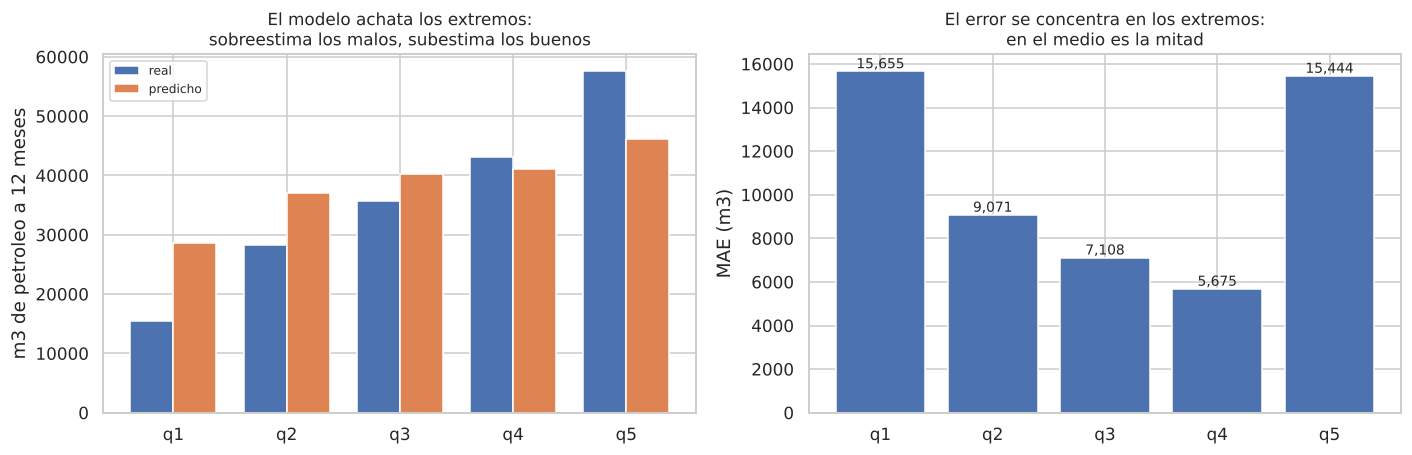

In [58]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
x = np.arange(len(por_quintil)); ancho = 0.38

ax[0].bar(x - ancho/2, por_quintil.real_mediana, ancho, label="real",
          color="#4C72B0")
ax[0].bar(x + ancho/2, por_quintil.predicho_mediana, ancho, label="predicho",
          color="#DD8452")
ax[0].set_xticks(x)
ax[0].set_xticklabels(["q1", "q2", "q3", "q4", "q5"])
ax[0].set_ylabel("m3 de petroleo a 12 meses")
ax[0].set_title("El modelo achata los extremos:\nsobreestima los malos, subestima los "
                "buenos", fontsize=11)
ax[0].legend(fontsize=8)

ax[1].bar(x, por_quintil.MAE, color="#4C72B0")
ax[1].set_xticks(x)
ax[1].set_xticklabels(["q1", "q2", "q3", "q4", "q5"])
ax[1].set_ylabel("MAE (m3)")
ax[1].set_title("El error se concentra en los extremos:\nen el medio es la mitad",
                fontsize=11)
for i, v in enumerate(por_quintil.MAE):
    ax[1].text(i, v, f"{v:,.0f}", ha="center", va="bottom", fontsize=9)

plt.tight_layout(); plt.show()

## Este es el resultado más útil para usar el modelo

El error **no está repartido parejo**:

| Quintil | Real (mediana) | Predicho (mediana) | MAE |
|---|---|---|---|
| q1 — menos productivos | 15.507 | 28.560 | **15.655** |
| q2 | 28.232 | 36.962 | 9.071 |
| q3 | 35.681 | 40.239 | **7.108** |
| q4 | 43.080 | 41.097 | **5.675** |
| q5 — más productivos | 57.521 | 46.060 | **15.444** |

En el **rango central** (q3 y q4) el MAE baja a **5.675-7.108 m³**, un 14-18% de la producción típica.
Eso es un error razonable para planificar.

En los **extremos** el MAE se triplica: **15.655 m³ en el quintil bajo y 15.444 en el alto**. Y el
sesgo es sistemático y de signo opuesto: al quintil malo le predice **13.000 m³ de más** y al bueno
**11.500 de menos**.

**La conclusión práctica:** el modelo sirve para estimar la producción esperada de un pozo de diseño
típico, y **no sirve para identificar de antemano los pozos excepcionales ni los fracasos**. Esos
casos son justamente los que no se explican por el diseño —se explican por la roca— y son los que
nuestros datos no pueden ver.

# 22. Conclusiones

## Lo que logramos

**Construimos la variable objetivo y el dataset de modelado.** Cruzando el diseño de fractura con la
producción mensual, y aplicando los dos guardas de truncamiento, llegamos a **1.917 pozos de
petróleo** con producción de 12 meses medida de forma comparable. Esto es lo que faltaba al cerrar
la Pre-entrega 2.

**Los modelos le ganan a la referencia por un margen claro.** Random Forest reduce el MAE de 14.138
a **10.596 m³**: un **25% menos de error** que predecir la mediana, con un R² de **0,263**.

**El feature engineering de la Pre-entrega 2 es lo que hace funcionar al modelo.** Con la longitud de
rama sola, el R² es negativo. Las variables de intensidad que construimos lo llevan a 0,161. Es la
contribución más concreta del trabajo propio del proyecto.

**El diseño de completación explica una parte real pero minoritaria de la productividad.** Los signos
de los coeficientes son coherentes con la física: ramas más largas, fracturas más densas y más
fluido por metro producen más. Pero la operadora —que es un proxy de la geología— pesa tanto como la
variable de diseño más importante.

## Lo que aprendimos sobre validación

Si hubiéramos partido los datos al azar, habríamos reportado **R² 0,52** en lugar de 0,26. Mismo
modelo, mismas variables, mismos hiperparámetros: exactamente el doble de rendimiento aparente, y
el factor se repite en los tres modelos. Lo único distinto es que la partición aleatoria le deja ver
al modelo pozos del mismo período que después usa para evaluarlo.

**La métrica no mide solo al modelo: mide al esquema de validación.** En un problema donde la
práctica cambia con el tiempo, una partición aleatoria no evalúa lo que el modelo va a tener que
hacer. Esto es lo que nos llevamos de la entrega.

El punto 15 lo confirma por un camino independiente y más limpio, porque no usa el conjunto de test:
con `cross_val_score` sobre los mismos pozos de entrenamiento, `KFold` da R² 0,546 y `TimeSeriesSplit`
da **0,171**. La validación aleatoria infla el resultado 3,2 veces, y los pozos de 2024-2025 no
participaron de esa medición.

**Y lo que no se puede arreglar con hiperparámetros, no se arregla.** El punto 16 recorrió 120
combinaciones con `GridSearchCV` y 60 sorteos con `RandomizedSearchCV`, las dos con validación
temporal. La mejor mejora el MAE de validación cruzada un 2,9% y **no mejora el test**: 10.659 m³
contra los 10.596 del modelo ajustado a mano. El R² del modelo optimizado, 0,256, cae dentro del
rango que cubre el mismo modelo cambiando solo la semilla del bosque (0,252 a 0,264). El techo no
está en el ajuste del modelo: está en los datos.

La misma lógica nos hizo **rechazar una variante que mejoraba la métrica**: agregar el año de
fractura sube el R² a 0,285, pero la mejora cambia de signo según el corte temporal y el mecanismo
que la produce —extrapolar a un valor que el modelo nunca vio— no es confiable. Preferimos el modelo
que explica menos por razones que se sostienen.

## Limitaciones, dichas con precisión

| Limitación | Alcance |
|---|---|
| **Falta la geología** | es el factor dominante y no está en datos abiertos. Es el techo del modelo, no un defecto del método |
| **R² de 0,263** | explica el 26% de la varianza: sirve para estimar el orden de magnitud, no para decidir sobre un pozo individual |
| **Falla en los extremos** | sobreestima el quintil bajo en 13.053 m³ y subestima el alto en 11.461. No detecta pozos excepcionales ni fracasos |
| **Validez temporal** | validado sobre pozos de 2024-2025. Si el diseño sigue cambiando, hay que reentrenar |
| **La operadora no es causal** | su peso refleja la calidad del área, no la habilidad de la empresa. No se puede usar para comparar operadoras |
| **191 pozos de gas afuera** | el modelo es de petróleo. Un modelo de gas es otro trabajo |

## Qué sigue

| Línea | Qué esperamos |
|---|---|
| **Encoding de alta cardinalidad** | `yacimiento` tiene 63 categorías y es un proxy geológico más fino que la operadora. El punto 11 ya midió que el target encoding empata con one-hot usando una columna en lugar de diez, así que es el camino; falta la validación cruzada anidada para no filtrar información |
| **Hiperparámetros, más allá del Random Forest** | el punto 16 cerró la búsqueda para el bosque: no hay nada que ganar. Queda abierta para Gradient Boosting, que tiene más parámetros sensibles (`learning_rate`, `max_iter`, `l2_regularization`) y donde la meseta puede ser menos plana |
| **Predecir el ratio productividad/costo** | la pregunta de negocio no es qué diseño produce más, sino cuál produce más por peso invertido. El dataset tiene las cantidades de arena y agua, que son el grueso del costo |
| **Intervalos de predicción** | dado el error en los extremos, un rango es más honesto que un número. Con `RandomForestQuantileRegressor` o regresión cuantílica |
| **Modelo de gas** | los 191 pozos excluidos, con la producción de gas como objetivo |

---

# Anexo: el recorte del archivo de producción

El dataset de producción de la Secretaría de Energía son archivos anuales que suman **1,4 GB**.
Lo que está en el repositorio es el resultado de este recorte, que deja **1,3 MB** con la misma
información útil para nuestro problema: solo los pozos de nuestro alcance y solo las cinco
columnas que usamos.

Se deja el código documentado para que el recorte sea auditable y reproducible.

```python
UMBRAL_RAMA_M = 500
FILAS_POR_BLOQUE = 500_000   # se lee por bloques: el archivo no entra en memoria

# 1. Los pozos del alcance, del dataset de fractura.
fr = pd.read_csv("fractura_adjunto_iv.csv", low_memory=False)
del_alcance = set(fr.loc[fr.longitud_rama_horizontal_m >= UMBRAL_RAMA_M, "idpozo"])

# 2. Los archivos anuales, leidos por bloques y filtrados sobre la marcha.
COLUMNAS = ["idpozo", "anio", "mes", "prod_pet", "prod_gas"]
partes = []
for archivo in sorted(Path("produccion").glob("*.csv")):
    for bloque in pd.read_csv(archivo, usecols=COLUMNAS, chunksize=FILAS_POR_BLOQUE):
        partes.append(bloque[bloque.idpozo.isin(del_alcance)])

# 3. Consolidacion: se suma por pozo-mes y se escribe comprimido.
prod = (pd.concat(partes)
        .groupby(["idpozo", "anio", "mes"], as_index=False)[["prod_pet", "prod_gas"]]
        .sum())
prod.to_csv("produccion_filtrada.csv.gz", index=False, compression="gzip")
```

Fuente: https://datos.energia.gob.ar/dataset/produccion-de-pozos-de-gas-y-petroleo-por-pozo-y-mes

---

## Datos usados en esta entrega

| Archivo | Origen | Contenido |
|---|---|---|
| `data/fractura_adjunto_iv.csv` | Secretaría de Energía — Adjunto IV | diseño de completación, 4.890 registros |
| `data/produccion_filtrada.csv.gz` | Secretaría de Energía — Producción por pozo y mes | 136.380 registros de pozo-mes, recorte propio |
| `data/pozos_ubicacion.csv` | Secretaría de Energía — Listado de pozos | coordenadas y cota, usado solo en el control del punto 19 |

**Proyecto Final — EnergIA Digital 2026 · Ciencia de Datos**

Franco Malacalza · Martín Gerbaldo · Carolina Bailón